<a href="https://colab.research.google.com/github/yonatan-ds/Tradeflow-AI/blob/main/Rout_Optimization_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# %% CELL 0 — Install, imports, configuration, helper functions
%pip -q install lightgbm scikit-learn scipy statsmodels networkx seaborn joblib
import json, re, shutil, hashlib, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import networkx as nx, joblib, lightgbm as lgb, sklearn, scipy, statsmodels
from scipy import stats
from scipy.optimize import brentq
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import cdist, squareform
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, precision_score, recall_score,
    f1_score, fbeta_score, average_precision_score, roc_auc_score, brier_score_loss, log_loss, matthews_corrcoef,
    balanced_accuracy_score, confusion_matrix, precision_recall_curve)
from IPython.display import display

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
CFG = dict(seed=20261026, n_zones=300, n_hours=24*45, start="2026-01-01", drift=0.15, missing_rate=0.03, knn=5,
           split_edges=[0, .55, .65, .75, .85, 1.0], gap_hours=24,
           vif_max=5.0, corr_max=0.80, selection_tol=0.01, probe_repeats=4, tune_iter=20,
           cost_fn=10, cost_fp=1, min_precision=0.30, alert_budget=0.10, conformal_alpha=0.10,
           halflife_days=14, n_boot=300, cooldown_hours=3, cooldown_delta=0.15, lambda_risk=2.0)
SEED = CFG["seed"]; rng = np.random.default_rng(SEED); np.random.seed(SEED)
OUT = Path("tradeflow_fr08_v5"); OUT.mkdir(exist_ok=True)
PAL = dict(blue="#2563EB", green="#16A34A", amber="#F59E0B", red="#DC2626", purple="#7C3AED", teal="#0D9488", slate="#475569")

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2*6371.0*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def knn_weights(coords, k=5):
    d = cdist(coords, coords); np.fill_diagonal(d, np.inf)
    nn = np.argsort(d, axis=1)[:, :k]; Wm = np.zeros((len(coords), len(coords)))
    for i, row in enumerate(nn): Wm[i, row] = 1.0/k
    return Wm

def morans_i(v, Wm, n_perm=499, seed=0):
    z = np.asarray(v, float) - np.mean(v)
    stat = lambda z: (len(z)/Wm.sum()) * (z @ Wm @ z) / (z @ z)
    I = stat(z); r = np.random.default_rng(seed)
    perm = np.array([stat(r.permutation(z)) for _ in range(n_perm)])
    return float(I), float((1+np.sum(np.abs(perm) >= abs(I)))/(n_perm+1))

def psi(a, b, bins=10):
    a, b = np.asarray(a, float), np.asarray(b, float); a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(np.unique(a)) <= bins:
        vals = np.union1d(np.unique(a), np.unique(b))
        pa = np.array([(a == v).mean() for v in vals]); pb = np.array([(b == v).mean() for v in vals])
    else:
        edges = np.unique(np.quantile(a, np.linspace(0, 1, bins+1))); edges[0], edges[-1] = -np.inf, np.inf
        pa = np.histogram(a, edges)[0]/len(a); pb = np.histogram(b, edges)[0]/len(b)
    pa, pb = np.clip(pa, 1e-6, None), np.clip(pb, 1e-6, None)
    return float(np.sum((pb-pa)*np.log(pb/pa)))

def ece(y, p, bins=10):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins+1)[1:-1]), 0, bins-1); e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean()*abs(y[m].mean()-p[m].mean())
    return float(e)

def cluster_bootstrap(ids, fn, n=150, seed=SEED):
    """Resample whole clusters (zones, or day-blocks) with replacement -> 95% CI. Respects within-cluster dependence."""
    r = np.random.default_rng(seed); uz = np.unique(ids)
    idx_by = {z: np.flatnonzero(ids == z) for z in uz}; out = []
    for _ in range(n):
        pick = r.choice(uz, len(uz), replace=True)
        out.append(fn(np.concatenate([idx_by[z] for z in pick])))
    return np.percentile(np.array(out), [2.5, 97.5], axis=0)

def corr_ratio(cat, num):
    d = pd.DataFrame({"c": np.asarray(cat), "x": np.asarray(num, float)}).dropna()
    g = d.groupby("c")["x"]; ssb = (g.count()*(g.mean()-d.x.mean())**2).sum(); sst = ((d.x-d.x.mean())**2).sum()
    return float(np.sqrt(ssb/sst)) if sst > 0 else 0.0

def vif_from_corr(X):
    C = np.atleast_2d(np.corrcoef(X.to_numpy(float), rowvar=False))
    return pd.Series(np.diag(np.linalg.pinv(C)), index=X.columns)

def cluster_order(c):
    d = 1 - c.abs().to_numpy().copy(); np.fill_diagonal(d, 0); d = (d + d.T)/2
    return c.columns[leaves_list(linkage(squareform(d, checks=False), "average"))]

def clean_names(names): return [re.sub(r"[^0-9a-zA-Z_]+", "_", n) for n in names]
def savefig(name): plt.tight_layout(); plt.savefig(OUT/name, dpi=150, bbox_inches="tight"); plt.show()
def show(df, cmap="RdYlGn", reverse=False):
    """Colour-scaled table in notebooks; plain table if styling is unavailable."""
    try: display(df.style.background_gradient(cmap=cmap + ("_r" if reverse else ""), axis=0).format(precision=4))
    except Exception: display(df)
def topk_stats(y, s, frac):
    k = max(1, int(round(frac*len(y)))); idx = np.argsort(-np.asarray(s), kind="stable")[:k]
    prec = float(np.asarray(y)[idx].mean()); rec = float(np.asarray(y)[idx].sum()/max(np.sum(y), 1))
    return dict(alert_frac=frac, precision=prec, recall=rec, lift=prec/max(float(np.mean(y)), 1e-12))

# ---------- colourful visual helpers ----------
def pretty_heatmap(c, title, fname, annot=True, order=True):
    """Lower-triangle heatmap. The upper triangle is MASKED because corr(X,Y)==corr(Y,X) (mirror image) and the
    diagonal is always 1: showing them adds no information and doubles the clutter."""
    if order: o = cluster_order(c); c = c.loc[o, o]
    n_ = len(c); sz = min(max(6.5, .42*n_ + 3), 16)
    fig, ax = plt.subplots(figsize=(sz*1.1, sz*.9))
    sns.heatmap(c, mask=np.triu(np.ones(c.shape, bool), 1), cmap=sns.diverging_palette(250, 12, s=90, l=48, as_cmap=True),
                center=0, vmin=-1, vmax=1, annot=annot and n_ <= 22, fmt=".2f", annot_kws=dict(size=8), linewidths=.6,
                linecolor="white", square=True, ax=ax, cbar_kws=dict(label="Spearman ρ", shrink=.75))
    ax.set_title(title + "\n(upper triangle hidden: it mirrors the lower one)", fontsize=12, fontweight="bold")
    plt.xticks(fontsize=8, rotation=90); plt.yticks(fontsize=8); savefig(fname)

def vif_bars(v, title, fname, top=30):
    v = v.sort_values(ascending=False).head(top)[::-1]
    cols = [PAL["red"] if x > 5 else PAL["amber"] if x > 2.5 else PAL["green"] for x in v.values]
    fig, ax = plt.subplots(figsize=(9, max(3, .3*len(v)+1)))
    ax.barh(v.index, v.values, color=cols); ax.axvline(5, c=PAL["red"], ls="--"); ax.axvline(2.5, c=PAL["amber"], ls=":")
    ax.set_title(title + "   (green ≤2.5 · amber 2.5–5 · red >5)", fontweight="bold"); ax.set_xlabel("VIF"); savefig(fname)

def pretty_confusion(y, a, title, fname):
    cm = confusion_matrix(y, a, labels=[0, 1]); rp = cm/cm.sum(1, keepdims=True)
    colors = np.array([["#BBF7D0", "#FECACA"], ["#FED7AA", "#4ADE80"]])       # TN, FP / FN, TP
    tags = np.array([["TN", "FP"], ["FN", "TP"]])
    fig, ax = plt.subplots(figsize=(6.4, 5))
    for i in range(2):
        for j in range(2):
            ax.add_patch(plt.Rectangle((j, 1-i), 1, 1, color=colors[i, j], ec="white", lw=4))
            ax.text(j+.5, 1.5-i, f"{tags[i, j]}\n{cm[i, j]:,}\n{rp[i, j]:.1%} of row", ha="center", va="center",
                    fontsize=13, fontweight="bold", color="#0F172A")
    ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.set_xticks([.5, 1.5]); ax.set_xticklabels(["Predicted: no alert", "Predicted: ALERT"])
    ax.set_yticks([.5, 1.5]); ax.set_yticklabels(["Actual: EVENT", "Actual: no event"]); ax.grid(False)
    ax.set_title(title, fontweight="bold"); savefig(fname)
print("Ready. Output dir:", OUT.resolve())

Ready. Output dir: /content/tradeflow_fr08_v5


In [2]:
# %% CELL 1 — Synthetic panel generator (unchanged logic, same seed -> same data)
HUBS = {"Addis Ababa":(9.03,38.74),"Modjo":(8.59,39.12),"Adama":(8.54,39.27),"Awash":(8.99,40.16),
 "Mille":(11.41,40.76),"Semera":(11.79,41.00),"Galafi":(11.71,41.83),"Djibouti Port":(11.59,43.14),
 "Dire Dawa":(9.59,41.86),"Dessie":(11.13,39.63)}
hub_names = list(HUBS); hub_xy = np.array(list(HUBS.values()))
Z, T = CFG["n_zones"], CFG["n_hours"]; n = Z*T
parent = rng.integers(0, len(hub_names), Z)
xy = hub_xy[parent] + rng.normal(0, [.08, .10], (Z, 2))
zones = pd.DataFrame({"zone_id":[f"ZONE-{i:04d}" for i in range(Z)], "latitude":xy[:,0],
                      "longitude":xy[:,1], "nearest_hub":[hub_names[i] for i in parent]})
W = knn_weights(xy, CFG["knn"])

hub_effect = {"Galafi":.6,"Semera":.5,"Mille":.4,"Awash":.3,"Dessie":.3,"Dire Dawa":.2}
u = rng.normal(0, .7, Z)
base = .6*u + .4*(W@u) + np.array([hub_effect.get(h, 0) for h in zones.nearest_hub])

levels, pw = np.arange(4), np.array([.70,.18,.08,.04])
ws = np.zeros((T, len(hub_names)), int); ws[0] = rng.choice(levels, len(hub_names), p=pw)
for t in range(1, T):
    stay = rng.random(len(hub_names)) < .90
    ws[t] = np.where(stay, ws[t-1], rng.choice(levels, len(hub_names), p=pw))

H = np.empty((T, Z)); h = base.copy()
drift_zone = np.isin(zones.nearest_hub, ["Galafi","Semera","Mille"]); drift_start = int(.80*T)
for t in range(T):
    shock = rng.normal(0, .35, Z); shock = .5*shock + .5*(W@shock)
    burst = (rng.random(Z) < .002) * rng.uniform(1, 2.5, Z)
    h = .90*h + .10*base + shock + burst
    H[t] = h + .25*np.sin(2*np.pi*((t % 24)-18)/24) + (CFG["drift"]*drift_zone if t >= drift_start else 0)

flat = lambda M: M.T.ravel(); rep_z = lambda v: np.repeat(np.asarray(v), T); tile_t = lambda v: np.tile(np.asarray(v), Z)
times = pd.date_range(CFG["start"], periods=T, freq="h")
Hf = flat(H); Hc = np.clip(Hf, -3, 4); wsev = flat(ws[:, parent])

src_levels = ["government_advisory","verified_crowdsourced","unverified_crowdsourced"]
zsrc = rng.choice(src_levels, Z, p=[.40,.45,.15])
src = np.where(rng.random(n) < .85, rep_z(zsrc), rng.choice(src_levels, n, p=[.40,.45,.15]))
rel = np.where(src=="government_advisory", rng.uniform(.90,1,n),
      np.where(src=="verified_crowdsourced", rng.uniform(.70,.95,n), rng.uniform(.10,.65,n)))
age = np.where(src=="government_advisory", rng.uniform(0,72,n), rng.uniform(0,48,n))
verified = np.where(src=="unverified_crowdsourced", rng.random(n) < .15, True)
active = (age < np.where(src=="government_advisory", 36, 12)) & verified

cargo = rng.choice(["General","Fuel","Food","Refrigerated","Construction"], n)
vehicle = rng.choice(["Heavy Truck","Container Truck","Tanker","Refrigerated Truck"], n)
road_z = rng.choice(["Highway","Paved","Unpaved"], Z, p=[.25,.55,.20]); cond_z = rng.uniform(.35, 1, Z)

sec_score = 100/(1+np.exp(-(Hf-.2+rng.normal(0,.45,n))))
incidents = rng.poisson(np.exp(.4+.5*Hc)); reports = rng.poisson(np.exp(.2+.4*Hc))
activity = np.clip(.45+.18*Hf+rng.normal(0,.18,n), 0, 1)
condition = np.clip(rep_z(cond_z)+rng.normal(0,.03,n), .25, 1)
dist = np.clip(rng.gamma(2.2,8,n), .2, 80); speed = np.clip(rng.normal(48,13,n), 8, 90)
eta = dist/speed*60

fuel = (cargo=="Fuel").astype(float); tanker = (vehicle=="Tanker").astype(float)
lin_r = 1.1*Hf + .30*fuel + .12*tanker + .30*wsev - .30
oracle_risk = 100/(1+np.exp(-lin_r))
risk = np.clip(oracle_risk + rng.normal(0, 3.5, n), 0, 100)
lin_e = 1.0*Hf + .25*wsev + .15*fuel
b0 = brentq(lambda b: (1/(1+np.exp(-(b+lin_e)))).mean() - .10, -15, 5)
oracle_p = 1/(1+np.exp(-(b0+lin_e))); event = rng.binomial(1, oracle_p)

def mask(a, rate):
    a = np.asarray(a, float).copy(); a[rng.random(len(a)) < rate] = np.nan; return a
mr = CFG["missing_rate"]; sec_obs = mask(sec_score, mr)
sec_cat = pd.Series(pd.cut(sec_obs, [-1,25,50,75,101], labels=["Low","Moderate","High","Critical"])).astype(object).fillna("Unknown").to_numpy()

rows = pd.DataFrame({
 "zone_id":rep_z(zones.zone_id), "timestamp":tile_t(times), "nearest_hub":rep_z(zones.nearest_hub),
 "hour_of_day":tile_t(times.hour), "day_of_week":tile_t(times.dayofweek),
 "distance_to_zone_km":dist, "approach_speed_kmh":speed, "eta_to_zone_minutes":eta,
 "weather_condition":np.array(["Dry","Rain","Fog","Severe Storm"])[wsev], "weather_severity":wsev,
 "road_type":rep_z(road_z), "road_condition_score":mask(condition, mr), "cargo_type":cargo, "vehicle_type":vehicle,
 "source_type":src, "source_reliability":rel, "reports_last_24h":mask(reports, mr),
 "historical_incidents_30d":mask(incidents, mr), "security_score":sec_obs, "security_category":sec_cat,
 "zone_activity_score":mask(activity, mr), "advisory_age_hours":mask(age, 2*mr),
 "report_verified":verified.astype(int), "active_advisory":active.astype(int),
 "noise_control":rng.normal(0,1,n),
 "target_risk_score":risk, "risk_event_next_60min":event,
 "oracle_risk_mean":oracle_risk, "oracle_event_prob":oracle_p})

REG_T, CLF_T = "target_risk_score", "risk_event_next_60min"
REQUIRED = ["zone_id","timestamp","nearest_hub","weather_severity","road_type","cargo_type","vehicle_type",
            "source_type","source_reliability","security_score","report_verified","active_advisory",REG_T,CLF_T]
assert all(c in rows for c in REQUIRED) and not rows.duplicated(["zone_id","timestamp"]).any()
assert rows[REG_T].between(0,100).all() and set(rows[CLF_T].unique()) <= {0,1}
rows.to_csv(OUT/"synthetic_panel.csv.gz", index=False, compression="gzip"); zones.to_csv(OUT/"zones.csv", index=False)
print("Panel:", rows.shape, "| prevalence:", round(rows[CLF_T].mean(),3), "| synthetic prototype")
display(rows.head(3))

Panel: (324000, 29) | prevalence: 0.1 | synthetic prototype


,zone_id,timestamp,nearest_hub,hour_of_day,day_of_week,distance_to_zone_km,approach_speed_kmh,eta_to_zone_minutes,weather_condition,weather_severity,...,security_category,zone_activity_score,advisory_age_hours,report_verified,active_advisory,noise_control,target_risk_score,risk_event_next_60min,oracle_risk_mean,oracle_event_prob
0,ZONE-0000,2026-01-01 00:00:00,Galafi,0,3,8.103373,49.340579,9.854006,Fog,2,...,High,0.981481,13.308340,1,1,0.933848,67.456844,0,69.773116,0.122236
1,ZONE-0000,2026-01-01 01:00:00,Galafi,1,3,26.924451,48.247223,33.483110,Fog,2,...,High,0.775734,54.142214,1,0,-0.477440,71.736984,0,72.939275,0.151691
2,ZONE-0000,2026-01-01 02:00:00,Galafi,2,3,4.323760,18.074521,14.353110,Fog,2,...,High,0.231003,NaN,1,0,-0.174283,73.113234,0,73.381584,0.140637


,missing_rate
road_condition_score,0.0301
reports_last_24h,0.0302
historical_incidents_30d,0.0295
security_score,0.0303
zone_activity_score,0.0308
advisory_age_hours,0.0600


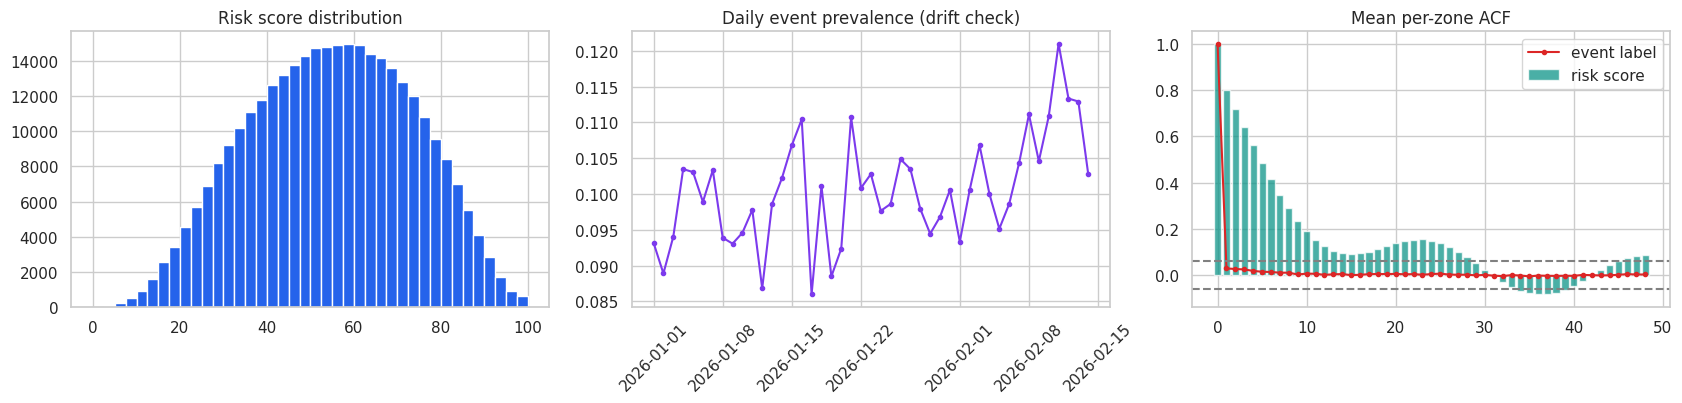

Lag-1 ACF risk=0.802, event=0.029 | Durbin-Watson=0.395 (2 = none)
Ljung-Box(24) rejects white noise in 100% of sampled zones
Moran's I (spatial) risk=0.401 (p=0.002), event=0.417 (p=0.002)
NOTE: these numbers describe the DATA. They do not mean the split is leaky. They mean a random row split WOULD leak,
      which is why every cell below uses purged temporal splits, causal (shift(1)) lags, and cluster bootstraps.


In [3]:
# %% CELL 2 — Dependence diagnostics (WHY we need temporal splits, causal lags, cluster bootstrap)
rows = rows.sort_values(["zone_id","timestamp"]).reset_index(drop=True)
assert (rows.groupby("zone_id").size() == T).all()
miss = rows.isna().mean(); display(miss[miss>0].round(4).to_frame("missing_rate"))

R = rows[REG_T].to_numpy().reshape(Z, T); E = rows[CLF_T].to_numpy().reshape(Z, T)
nl = 48
acf_r = np.mean([acf(R[i], nlags=nl, fft=True) for i in range(Z)], axis=0)
acf_e = np.mean([acf(E[i], nlags=nl, fft=True) for i in range(Z)], axis=0)
ci95 = 1.96/np.sqrt(T)
lb = [acorr_ljungbox(R[i], lags=[24], return_df=True)["lb_pvalue"].iloc[0] for i in range(0, Z, 5)]
dw = np.mean([durbin_watson(R[i]-R[i].mean()) for i in range(Z)])
I_r, p_r = morans_i(R.mean(1), W); I_e, p_e = morans_i(E.mean(1), W)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].hist(rows[REG_T], bins=40, color=PAL["blue"]); ax[0].set_title("Risk score distribution")
daily = rows.groupby(rows.timestamp.dt.date)[CLF_T].mean(); ax[1].plot(daily.index, daily.values, marker="o", ms=3, color=PAL["purple"])
ax[1].set_title("Daily event prevalence (drift check)"); ax[1].tick_params(axis="x", rotation=45)
ax[2].bar(range(nl+1), acf_r, alpha=.75, color=PAL["teal"], label="risk score"); ax[2].plot(range(nl+1), acf_e, "o-", ms=3, color=PAL["red"], label="event label")
ax[2].axhline(ci95, ls="--", c="gray"); ax[2].axhline(-ci95, ls="--", c="gray"); ax[2].set_title("Mean per-zone ACF"); ax[2].legend()
savefig("eda_autocorrelation.png")
print(f"Lag-1 ACF risk={acf_r[1]:.3f}, event={acf_e[1]:.3f} | Durbin-Watson={dw:.3f} (2 = none)")
print(f"Ljung-Box(24) rejects white noise in {np.mean(np.array(lb)<.05):.0%} of sampled zones")
print(f"Moran's I (spatial) risk={I_r:.3f} (p={p_r:.3f}), event={I_e:.3f} (p={p_e:.3f})")
print("NOTE: these numbers describe the DATA. They do not mean the split is leaky. They mean a random row split WOULD leak,")
print("      which is why every cell below uses purged temporal splits, causal (shift(1)) lags, and cluster bootstraps.")

In [4]:
# %% CELL 3 — Causal feature engineering (+ new smoothing features to absorb residual autocorrelation)
df = rows.copy(); g = df.groupby("zone_id", sort=False)
assert (df.zone_id.iloc[::T].to_numpy() == zones.zone_id.to_numpy()).all()
BASE_DYN = ["security_score","historical_incidents_30d","reports_last_24h","zone_activity_score"]
for c in BASE_DYN:                                          # every statistic uses shift(1): nothing from the current row
    df[f"{c}_lag1"]  = g[c].shift(1)
    df[f"{c}_roll6"] = g[c].transform(lambda x: x.shift(1).rolling(6,  min_periods=3).mean())
    df[f"{c}_roll24"]= g[c].transform(lambda x: x.shift(1).rolling(24, min_periods=12).mean())
# NEW: exponentially-weighted means = a causal "filter" of the latent risk, and a zone-level long-run mean
for c in ["security_score", "zone_activity_score"]:
    for span in (3, 12):
        df[f"{c}_ewm{span}"] = g[c].transform(lambda x, s=span: x.shift(1).ewm(span=s, adjust=False).mean())
df["security_score_lag2"] = g["security_score"].shift(2)
df["security_score_zmean"] = g["security_score"].transform(lambda x: x.shift(1).expanding(min_periods=12).mean())
ev = g[CLF_T]
df["event_lag1"]  = ev.shift(1)
df["event_roll6"] = ev.transform(lambda x: x.shift(1).rolling(6,  min_periods=1).sum())
df["event_roll24"]= ev.transform(lambda x: x.shift(1).rolling(24, min_periods=1).sum())
# FIX: forward-fill ONLY (the old .bfill() copied FUTURE values into early hours). Leading NaNs get a neutral constant.
S = pd.DataFrame(df.security_score.to_numpy().reshape(Z, T).T).ffill().fillna(50.0).to_numpy().T
NB = W @ S                                                  # neighbours' security at the same hour
NBl = np.full_like(NB, np.nan); NBl[:, 1:] = NB[:, :-1]
df["neighbor_security_lag1"] = NBl.ravel()                  # spatial lag of the PREVIOUS hour
df["neighbor_security_roll6"] = pd.DataFrame(NB.T).shift(1).rolling(6, min_periods=3).mean().to_numpy().T.ravel()
for nm, per in [("hour",24),("dow",7)]:
    col = df.hour_of_day if nm == "hour" else df.day_of_week
    df[f"{nm}_sin"] = np.sin(2*np.pi*col/per); df[f"{nm}_cos"] = np.cos(2*np.pi*col/per)
df = df[df.timestamp >= times[24]].reset_index(drop=True)

def audit_causality(n_checks=200):
    """Recompute security_score_roll6 by hand from strictly-past raw rows; any mismatch = leakage."""
    r = np.random.default_rng(1); bad = 0; raw = rows.set_index(["zone_id", "timestamp"]).security_score
    for _ in range(n_checks):
        i = int(r.integers(len(df))); z, t = df.zone_id.iat[i], df.timestamp.iat[i]
        past = raw.loc[z].loc[t - pd.Timedelta(hours=6): t - pd.Timedelta(hours=1)]
        exp = past.mean() if past.notna().sum() >= 3 else np.nan; got = df["security_score_roll6"].iat[i]
        bad += not ((np.isnan(exp) and np.isnan(got)) or np.isclose(exp, got))
    return bad
print("Causality audit — mismatches vs hand-computed strictly-past rolling mean:", audit_causality(), "(0 = no leakage)")

LAG_FEATS = [f"{c}_{s}" for c in BASE_DYN for s in ("lag1","roll6","roll24")] + \
            [f"{c}_ewm{s}" for c in ["security_score","zone_activity_score"] for s in (3,12)] + \
            ["security_score_lag2","security_score_zmean","event_lag1","event_roll6","event_roll24",
             "neighbor_security_lag1","neighbor_security_roll6"]
BASE_NUM = ["distance_to_zone_km","approach_speed_kmh","weather_severity","road_condition_score","source_reliability",
            "reports_last_24h","historical_incidents_30d","security_score","zone_activity_score","advisory_age_hours",
            "report_verified","active_advisory","noise_control","hour_sin","hour_cos","dow_sin","dow_cos"]
NUM_CAND = BASE_NUM + LAG_FEATS
CAT = ["nearest_hub","road_type","cargo_type","vehicle_type","source_type"]
EXCLUDED = {"eta_to_zone_minutes":"derived from distance/speed","weather_condition":"recode of weather_severity",
            "security_category":"binned security_score","hour_of_day/day_of_week":"replaced by cyclic terms",
            "oracle_*":"synthetic ground truth","zone_id":"identifier (would memorise zones)"}
print(f"{len(NUM_CAND)} numeric + {len(CAT)} categorical candidates")

Causality audit — mismatches vs hand-computed strictly-past rolling mean: 0 (0 = no leakage)
40 numeric + 5 categorical candidates


In [5]:
# %% CELL 4 — Purged chronological split: train | valid | calib | thresh | test (24h gap between blocks)
t0, t1 = df.timestamp.min(), df.timestamp.max(); span = t1 - t0; gap = pd.Timedelta(hours=CFG["gap_hours"])
names = ["train","valid","calib","thresh","test"]; edges = CFG["split_edges"]; df["split"] = "gap"
for k, nm in enumerate(names):
    lo = t0 + span*edges[k] + (gap if k > 0 else pd.Timedelta(0)); hi = t0 + span*edges[k+1]
    df.loc[(df.timestamp >= lo) & ((df.timestamp <= hi) if k == 4 else (df.timestamp < hi)), "split"] = nm
parts = {nm: df[df.split == nm].copy() for nm in names}
tr, va, ca, th, te = (parts[k] for k in names)
show(pd.DataFrame({k: dict(rows=len(v), start=v.timestamp.min(), end=v.timestamp.max(), event_rate=round(v[CLF_T].mean(),4))
                   for k, v in parts.items()}).T, cmap="Blues")
assert tr.timestamp.max() < va.timestamp.min() < ca.timestamp.min() < th.timestamp.min() < te.timestamp.min()

,rows,start,end,event_rate
train,174300,2026-01-02 00:00:00,2026-01-26 04:00:00,0.0982
valid,24300,2026-01-27 05:00:00,2026-01-30 13:00:00,0.0971
calib,24600,2026-01-31 14:00:00,2026-02-03 23:00:00,0.1002
thresh,24300,2026-02-05 00:00:00,2026-02-08 08:00:00,0.1012
test,40500,2026-02-09 09:00:00,2026-02-14 23:00:00,0.1108


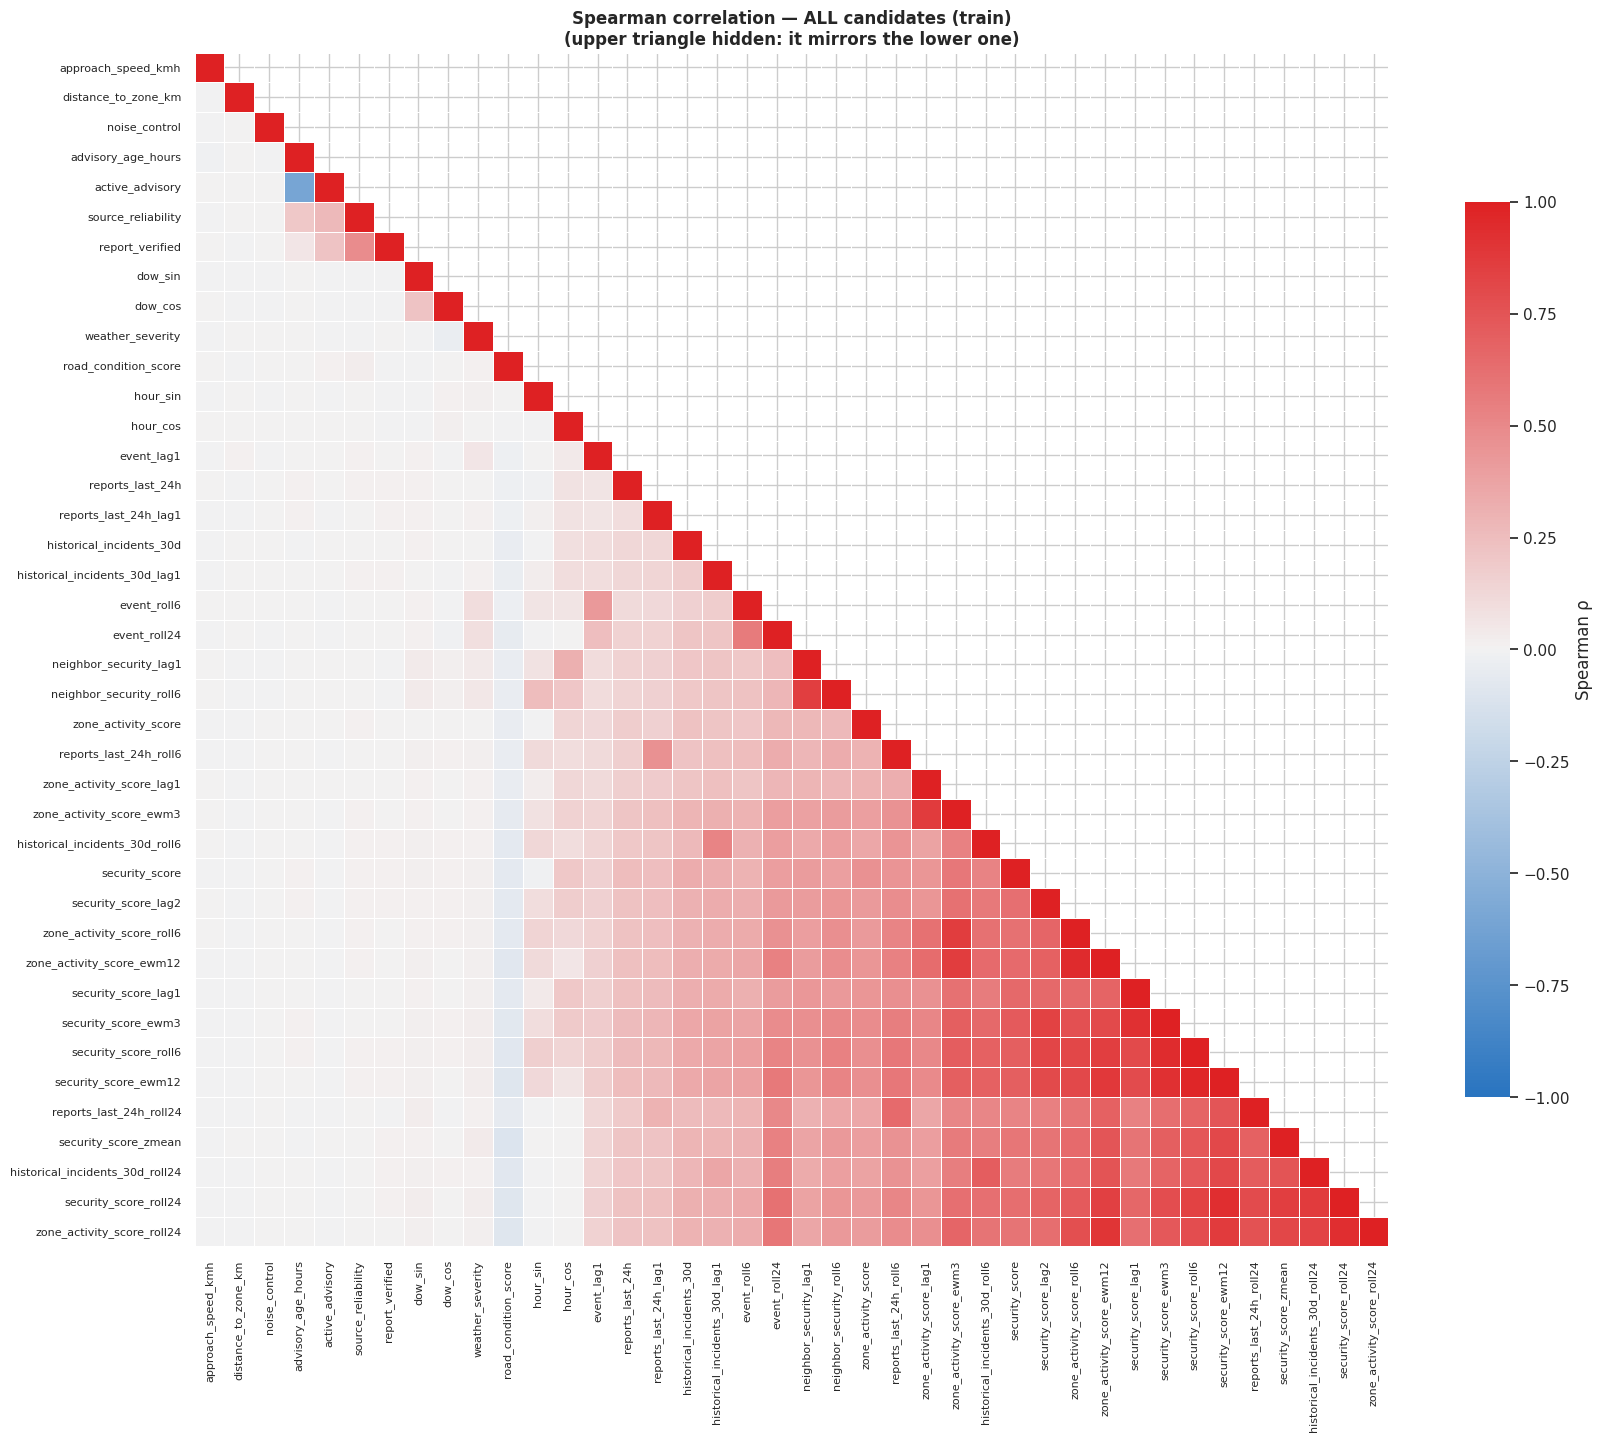

Stage A: 29 numeric pairs with |rho| >= 0.8


,feature_1,feature_2,rho
0,security_score_roll6,security_score_ewm12,0.9711
1,zone_activity_score_roll6,zone_activity_score_ewm12,0.9497
2,security_score_roll6,security_score_ewm3,0.9421
3,security_score_roll24,zone_activity_score_roll24,0.9340
4,security_score_roll24,security_score_ewm12,0.9317
5,security_score_lag1,security_score_ewm3,0.9271
6,security_score_ewm3,security_score_ewm12,0.9245
7,zone_activity_score_roll24,zone_activity_score_ewm12,0.9021
8,security_score_ewm12,zone_activity_score_ewm12,0.8858
9,zone_activity_score_lag1,zone_activity_score_ewm3,0.8716


Stage A2 drops: [{'dropped': 'report_verified', 'kind': 'numeric', 'kept': 'source_type', 'eta': 0.912}, {'dropped': 'source_reliability', 'kind': 'numeric', 'kept': 'source_type', 'eta': 0.909}]
Stage B (VIF) drops:


""


,VIF_all_candidates,VIF_after,assoc_with_targets,status
security_score_ewm12,180.983,NaN,0.483,dropped: pair correlation
security_score_ewm3,103.792,3.905,0.496,kept
zone_activity_score_ewm12,88.832,NaN,0.447,dropped: pair correlation
security_score_roll6,59.586,NaN,0.483,dropped: pair correlation
security_score_roll24,51.009,NaN,0.437,dropped: pair correlation
zone_activity_score_roll24,28.260,NaN,0.418,dropped: pair correlation
zone_activity_score_ewm3,26.245,NaN,0.403,dropped: pair correlation
security_score_lag1,24.394,NaN,0.448,dropped: pair correlation
zone_activity_score_roll6,21.618,NaN,0.424,dropped: pair correlation
security_score_lag2,7.660,NaN,0.426,dropped: pair correlation


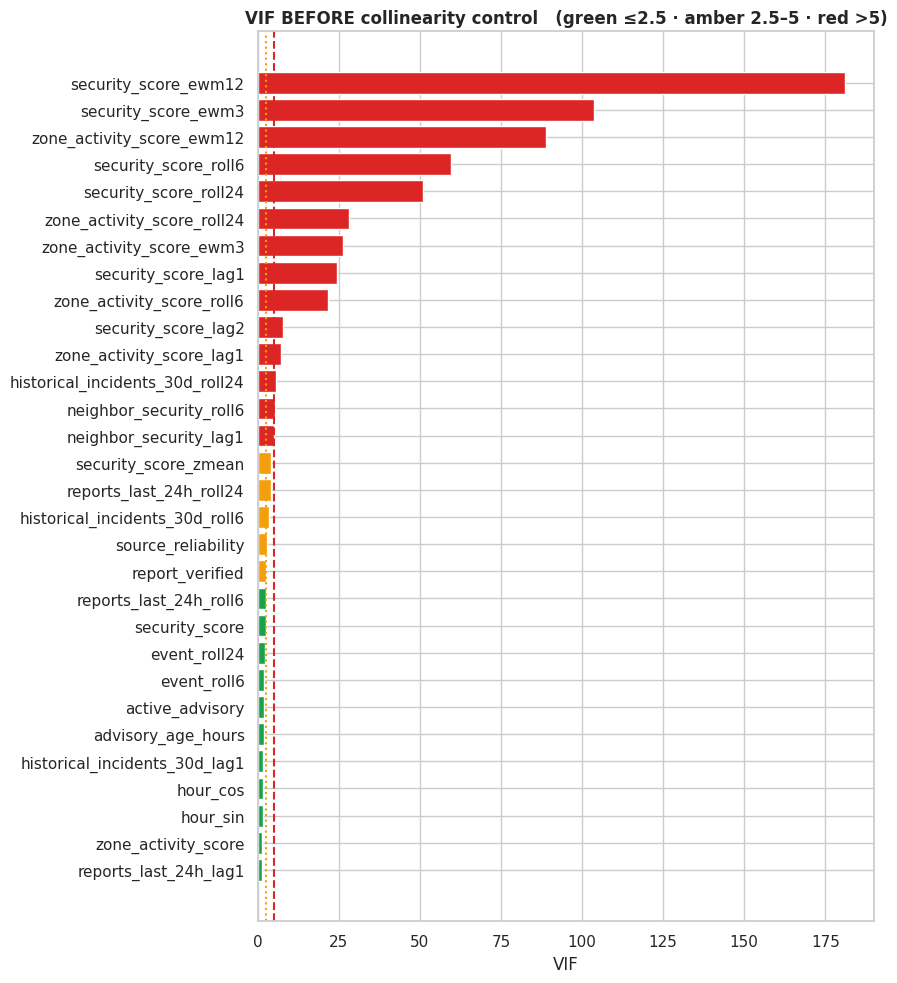

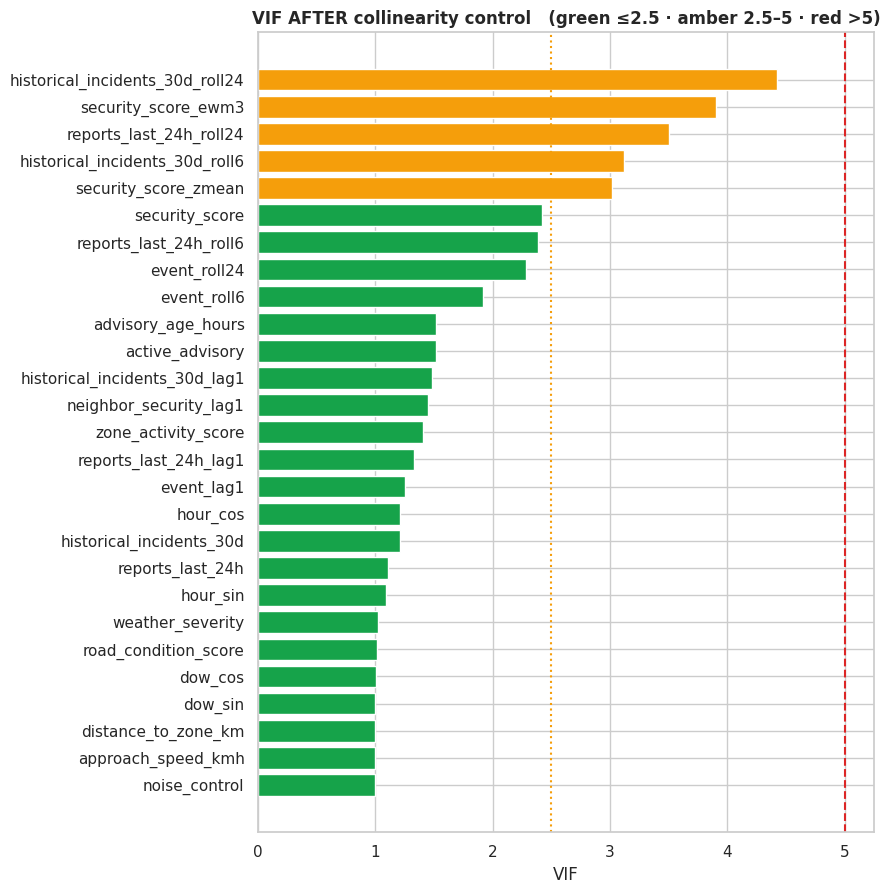

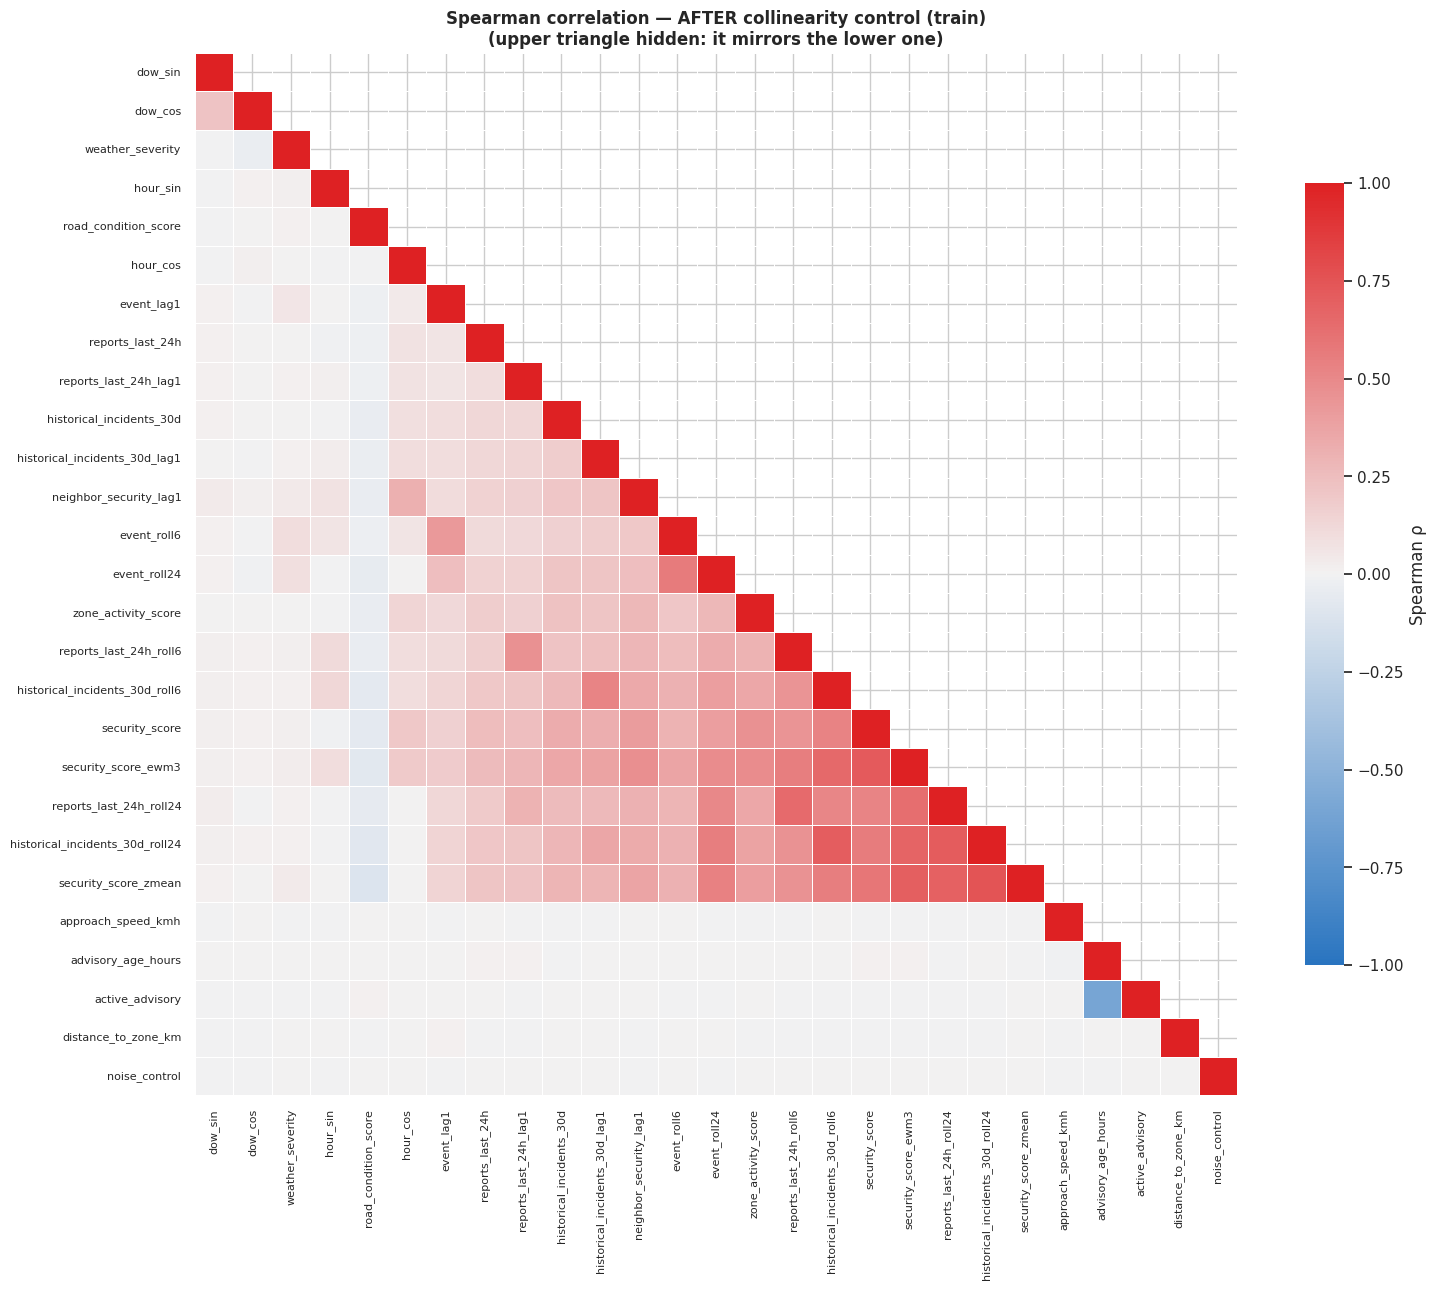

Condition number 4,035.5 -> 45.6 | max |rho| 0.753 | max VIF 4.43
Stage-1 survivors: 27 numeric + 5 categorical


In [6]:
# %% CELL 5 — Collinearity control: pair correlation -> categorical overlap -> VIF
Xs = tr[NUM_CAND].sample(min(60000, len(tr)), random_state=SEED)
Xs = Xs.fillna(Xs.median()); Xs = Xs.loc[:, Xs.nunique() > 1]
sidx = Xs.index; Xr = Xs.rank()
ys_r, ys_c = tr.loc[sidx, REG_T], tr.loc[sidx, CLF_T]
assoc = pd.Series({c: .5*(abs(stats.spearmanr(Xs[c], ys_r)[0]) + abs(stats.spearmanr(Xs[c], ys_c)[0])) for c in Xs.columns}).fillna(0)
cat_s = tr.loc[sidx, CAT]
assoc_cat = pd.Series({c: .5*(corr_ratio(cat_s[c], ys_r) + corr_ratio(cat_s[c], ys_c)) for c in CAT})

def hi_pairs(c, thr):
    p = c.where(np.triu(np.ones(c.shape, bool), 1)).stack().reset_index()
    p.columns = ["feature_1", "feature_2", "rho"]; p["abs_rho"] = p["rho"].abs()
    return p[p["abs_rho"] >= thr].sort_values("abs_rho", ascending=False).reset_index(drop=True)
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    if min(ct.shape) < 2: return 0.0
    return float(np.sqrt(stats.chi2_contingency(ct)[0] / (ct.to_numpy().sum()*(min(ct.shape)-1))))

pretty_heatmap(Xr.corr(), "Spearman correlation — ALL candidates (train)", "corr_before.png", annot=False)
high = hi_pairs(Xr.corr(), CFG["corr_max"]); print(f"Stage A: {len(high)} numeric pairs with |rho| >= {CFG['corr_max']}"); show(high.drop(columns="abs_rho"), "Reds")
dropA, logA = set(), []
for _, r in high.iterrows():
    f1, f2 = r["feature_1"], r["feature_2"]
    if f1 in dropA or f2 in dropA: continue
    d = f1 if assoc[f1] < assoc[f2] else f2
    dropA.add(d); logA.append(dict(dropped=d, kept=f2 if d == f1 else f1, rho=round(float(r["rho"]), 3), assoc_dropped=round(float(assoc[d]), 3)))
keep = [c for c in Xs.columns if c not in dropA]

cat_keep, logC = list(CAT), []
cv = pd.DataFrame([dict(a=x, b=y, V=cramers_v(cat_s[x], cat_s[y])) for i, x in enumerate(CAT) for y in CAT[i+1:]])
for _, r in cv[cv.V >= CFG["corr_max"]].sort_values("V", ascending=False).iterrows():
    if r["a"] in cat_keep and r["b"] in cat_keep:
        d = r["a"] if assoc_cat[r["a"]] < assoc_cat[r["b"]] else r["b"]; cat_keep.remove(d); logC.append(dict(dropped=d, V=round(float(r["V"]), 3)))
mixed = pd.DataFrame([dict(categorical=c, numeric=nn, eta=corr_ratio(cat_s[c], Xs[nn])) for c in cat_keep for nn in keep])
logM = []
for _, r in mixed[mixed.eta >= CFG["corr_max"]].sort_values("eta", ascending=False).iterrows():
    c, nn = r["categorical"], r["numeric"]
    if c not in cat_keep or nn not in keep: continue
    if assoc_cat[c] < assoc[nn]: cat_keep.remove(c); logM.append(dict(dropped=c, kind="categorical", kept=nn, eta=round(float(r["eta"]), 3)))
    else: keep.remove(nn); logM.append(dict(dropped=nn, kind="numeric", kept=c, eta=round(float(r["eta"]), 3)))
print("Stage A2 drops:", logC + logM)

def prune_vif(cols, thr):
    kept, log = list(cols), []
    while len(kept) > 2:
        v = vif_from_corr(Xs[kept]); worst = v.idxmax()
        if v[worst] <= thr: break
        c = Xr[kept].corr().abs()[worst].drop(worst)
        group = [worst] + list(c[c >= .5].sort_values(ascending=False).head(3).index)
        drop = min(group, key=lambda f: assoc[f])
        log.append(dict(step=len(log)+1, worst_vif_feature=worst, worst_vif=round(float(v[worst]), 2), dropped=drop,
                        assoc_dropped=round(float(assoc[drop]), 3), remaining=len(kept)-1))
        kept.remove(drop)
    return kept, pd.DataFrame(log)
NUM_S1, logB = prune_vif(keep, CFG["vif_max"]); CAT_S1 = list(cat_keep)
print("Stage B (VIF) drops:"); display(logB)

vif_all, vif_fin = vif_from_corr(Xs[list(Xs.columns)]), vif_from_corr(Xs[NUM_S1])
status = {f: "dropped: pair correlation" for f in dropA}
status.update({d["dropped"]: "dropped: categorical overlap" for d in logM if d["kind"] == "numeric"})
if len(logB): status.update({f: "dropped: VIF" for f in logB["dropped"]})
vif_cmp = pd.DataFrame({"VIF_all_candidates": vif_all, "VIF_after": vif_fin, "assoc_with_targets": assoc})
vif_cmp["status"] = [status.get(f, "kept") for f in vif_cmp.index]
display(vif_cmp.sort_values("VIF_all_candidates", ascending=False).round(3))
vif_bars(vif_all, "VIF BEFORE collinearity control", "vif_before.png"); vif_bars(vif_fin, "VIF AFTER collinearity control", "vif_after.png")
pretty_heatmap(Xr[NUM_S1].corr(), "Spearman correlation — AFTER collinearity control (train)", "corr_after.png", annot=False)
cond = lambda cols: np.linalg.cond(np.corrcoef(Xs[cols].to_numpy(float), rowvar=False))
mx = Xr[NUM_S1].corr().abs().where(~np.eye(len(NUM_S1), dtype=bool)).max().max()
print(f"Condition number {cond(list(Xs.columns)):,.1f} -> {cond(NUM_S1):,.1f} | max |rho| {mx:.3f} | max VIF {vif_fin.max():.2f}")
print(f"Stage-1 survivors: {len(NUM_S1)} numeric + {len(CAT_S1)} categorical")
vif_cmp.to_csv(OUT/"vif_before_after.csv"); high.to_csv(OUT/"high_corr_pairs.csv", index=False); logB.to_csv(OUT/"vif_pruning_log.csv", index=False)

,reg_imp,reg_std,clf_imp,clf_std,combined,pass_probe
security_score_ewm3,4.56770,0.02660,0.02234,0.00331,0.93910,True
security_score,3.34231,0.02778,0.02544,0.00271,0.86586,True
weather_severity,1.64558,0.01110,0.00951,0.00037,0.36708,True
cargo_type,0.71201,0.01206,0.00209,0.00043,0.11908,True
zone_activity_score,0.34540,0.00527,0.00195,0.00023,0.07613,True
security_score_zmean,0.41308,0.00788,0.00141,0.00078,0.07301,True
hour_sin,0.11419,0.01162,0.00075,0.00028,0.02725,True
noise_control,-0.00016,0.00016,0.00135,0.00029,0.02648,False
probe_gauss_a,0.00009,0.00004,0.00111,0.00029,0.02180,False
historical_incidents_30d,0.13495,0.00457,0.00030,0.00061,0.02070,True


Probe thresholds: regression 0.00017 | classification 0.00193
23 features beat the probes. Negative controls removed: ['distance_to_zone_km', 'approach_speed_kmh', 'noise_control']


,k,last_added,valid_MAE,valid_PR_AUC
0,3,weather_severity,6.36675,0.20250
1,4,cargo_type,6.01187,0.20280
2,5,zone_activity_score,5.84741,0.20494
3,6,security_score_zmean,5.72537,0.20361
4,8,historical_incidents_30d,5.57462,0.20554
5,10,reports_last_24h,5.50433,0.20812
6,12,historical_incidents_30d_roll6,5.40607,0.20786
7,15,event_lag1,5.39195,0.20730
8,18,historical_incidents_30d_lag1,5.36985,0.20812
9,23,event_roll24,5.36347,0.20674


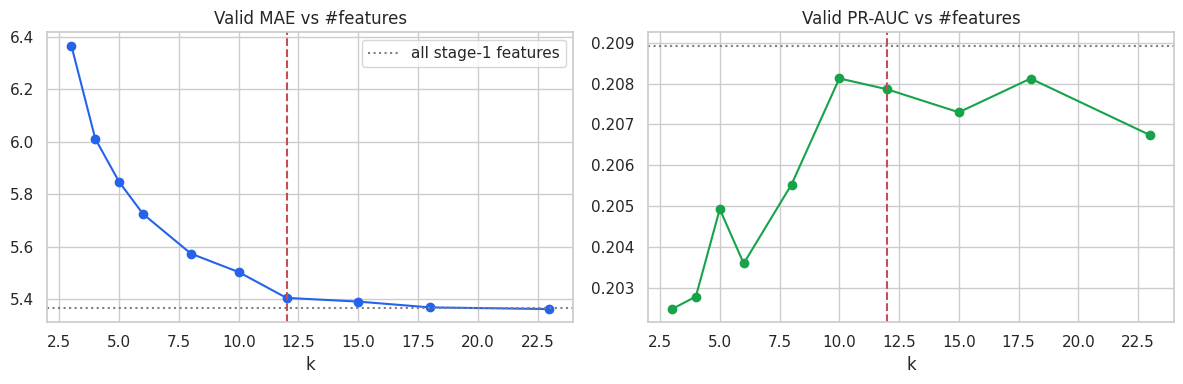

SELECTED 12/32 features: ['security_score_ewm3', 'security_score', 'weather_severity', 'zone_activity_score', 'security_score_zmean', 'hour_sin', 'historical_incidents_30d', 'neighbor_security_lag1', 'reports_last_24h', 'historical_incidents_30d_roll6', 'cargo_type', 'vehicle_type']
vs all stage-1 features -> MAE 5.406 vs 5.366 | PR-AUC 0.2079 vs 0.2089
CERTIFICATE ✓ max VIF = 3.65 (≤ 5.0) | max |rho| = 0.720 (< 0.8)


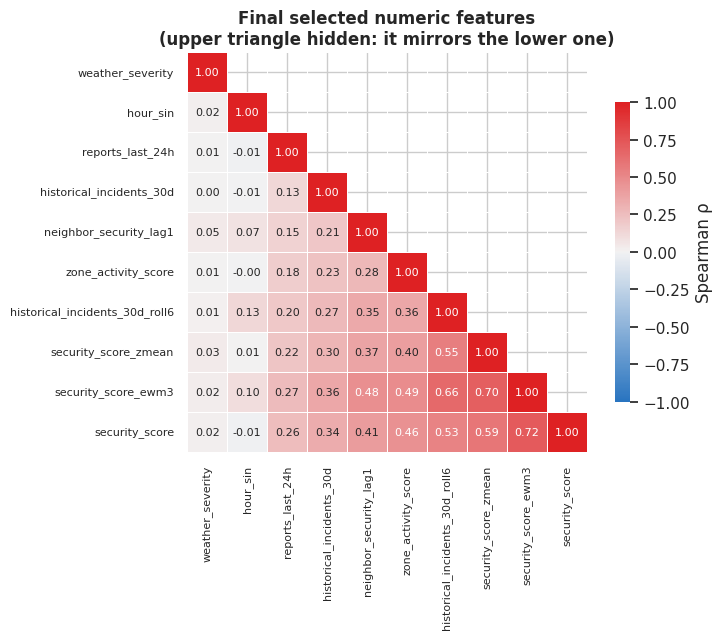

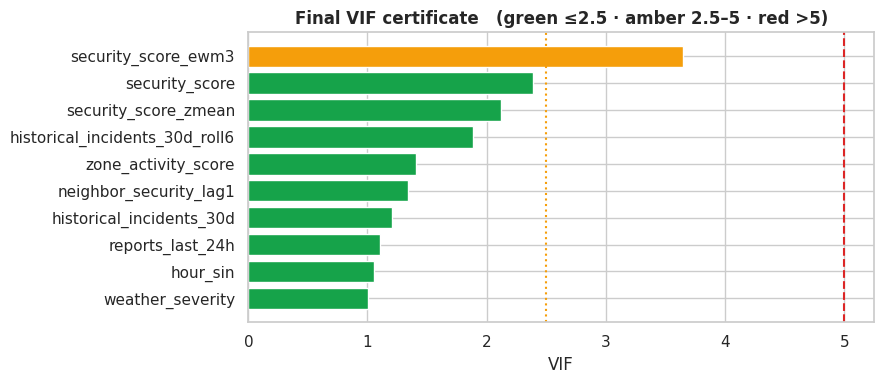

,feature,type,rank,combined_importance,VIF
0,security_score_ewm3,numeric,1,0.9391,3.65
1,security_score,numeric,2,0.8659,2.39
2,weather_severity,numeric,3,0.3671,1.00
3,cargo_type,categorical,4,0.1191,NaN
4,zone_activity_score,numeric,5,0.0761,1.41
5,security_score_zmean,numeric,6,0.0730,2.12
6,hour_sin,numeric,7,0.0272,1.05
7,historical_incidents_30d,numeric,8,0.0207,1.20
8,neighbor_security_lag1,numeric,9,0.0179,1.34
9,reports_last_24h,numeric,10,0.0159,1.11


In [7]:
# %% CELL 6 — Preprocessing factory + probe-based selection + feature ladder
def make_pre(num, cat):
    tfs = []
    if num: tfs.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), num))
    if cat:
        try: ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        except TypeError: ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
        tfs.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]), cat))
    return ColumnTransformer(tfs)

def design(num, cat):                                           # fitted on TRAIN only
    pre_ = make_pre(num, cat).fit(tr[num + cat]); names_ = clean_names(pre_.get_feature_names_out())
    return pre_, names_, (lambda d: pd.DataFrame(pre_.transform(d[num + cat]), columns=names_, index=d.index))

SEL_KW = dict(n_estimators=300, learning_rate=.05, num_leaves=15, min_child_samples=300, subsample=.8, subsample_freq=1,
              colsample_bytree=.7, reg_lambda=10, random_state=SEED, n_jobs=-1, verbosity=-1)
LAD_KW = {**SEL_KW, "n_estimators": 250, "learning_rate": .08}

probe_rng = np.random.default_rng(SEED + 99)
def add_probes(d):
    d = d.copy(); d["probe_gauss_a"] = probe_rng.normal(size=len(d)); d["probe_gauss_b"] = probe_rng.normal(size=len(d))
    d["probe_cat"] = probe_rng.choice(list("ABCD"), len(d)); return d
tr_s, va_s = add_probes(tr), add_probes(va)
sel_num, sel_cat = NUM_S1 + ["probe_gauss_a", "probe_gauss_b"], CAT_S1 + ["probe_cat"]; cols = sel_num + sel_cat
sel_r = Pipeline([("pre", make_pre(sel_num, sel_cat)), ("m", lgb.LGBMRegressor(**SEL_KW))]).fit(tr_s[cols], tr_s[REG_T])
sel_c = Pipeline([("pre", make_pre(sel_num, sel_cat)), ("m", lgb.LGBMClassifier(**SEL_KW))]).fit(tr_s[cols], tr_s[CLF_T])
vs = va_s.sample(min(15000, len(va_s)), random_state=SEED)
pi_r = permutation_importance(sel_r, vs[cols], vs[REG_T], scoring="neg_mean_absolute_error", n_repeats=CFG["probe_repeats"], random_state=SEED, n_jobs=1)
pi_c = permutation_importance(sel_c, vs[cols], vs[CLF_T], scoring="average_precision", n_repeats=CFG["probe_repeats"], random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"reg_imp": pi_r.importances_mean, "reg_std": pi_r.importances_std,
                    "clf_imp": pi_c.importances_mean, "clf_std": pi_c.importances_std}, index=cols)
PROBES = [p for p in ["probe_gauss_a", "probe_gauss_b", "probe_cat", "noise_control"] if p in imp.index]
thr_r = max(0.0, float((imp.loc[PROBES, "reg_imp"] + 2*imp.loc[PROBES, "reg_std"]).max()))
thr_c = max(0.0, float((imp.loc[PROBES, "clf_imp"] + 2*imp.loc[PROBES, "clf_std"]).max()))
rn = imp.reg_imp.clip(lower=0)/(imp.reg_imp.clip(lower=0).max() + 1e-12)
cn = imp.clf_imp.clip(lower=0)/(imp.clf_imp.clip(lower=0).max() + 1e-12)
imp["combined"] = .5*(rn + cn); imp["pass_probe"] = (imp.reg_imp > thr_r) | (imp.clf_imp > thr_c)
display(imp.sort_values("combined", ascending=False).round(5)); print(f"Probe thresholds: regression {thr_r:.5f} | classification {thr_c:.5f}")
pool = [f for f in imp.index if imp.loc[f, "pass_probe"] and f not in PROBES]
if len(pool) < 3: pool = [f for f in imp.sort_values("combined", ascending=False).index if f not in PROBES][:5]
ranking = imp.loc[pool].sort_values("combined", ascending=False)
controls_removed = [c for c in ["distance_to_zone_km", "approach_speed_kmh", "noise_control"] if c not in pool]
print(f"{len(pool)} features beat the probes. Negative controls removed: {controls_removed}")

def fit_eval(feats):
    num = [f for f in feats if f in NUM_S1]; cat = [f for f in feats if f in CAT_S1]
    _, _, f_ = design(num, cat); Xa, Xb = f_(tr), f_(va)
    r = lgb.LGBMRegressor(**LAD_KW).fit(Xa, tr[REG_T]); c = lgb.LGBMClassifier(**LAD_KW).fit(Xa, tr[CLF_T])
    return mean_absolute_error(va[REG_T], r.predict(Xb)), average_precision_score(va[CLF_T], c.predict_proba(Xb)[:, 1])
ks = sorted(set([k for k in (3, 4, 5, 6, 8, 10, 12, 15, 18) if k < len(pool)] + [len(pool)]))
lad = pd.DataFrame([dict(k=k, last_added=ranking.index[k-1], **dict(zip(["valid_MAE", "valid_PR_AUC"], fit_eval(list(ranking.index[:k]))))) for k in ks])
tol = CFG["selection_tol"]
okk = lad[(lad.valid_MAE <= lad.valid_MAE.min()*(1+tol)) & (lad.valid_PR_AUC >= lad.valid_PR_AUC.max()*(1-tol))]
k_star = int(okk.k.min()) if len(okk) else int(lad.k.max())
mae_all, pr_all = fit_eval(NUM_S1 + CAT_S1); display(lad.round(5))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(lad.k, lad.valid_MAE, "o-", color=PAL["blue"]); ax[0].axhline(mae_all, ls=":", c="gray", label="all stage-1 features"); ax[0].axvline(k_star, c="r", ls="--"); ax[0].set(title="Valid MAE vs #features", xlabel="k"); ax[0].legend()
ax[1].plot(lad.k, lad.valid_PR_AUC, "o-", color=PAL["green"]); ax[1].axhline(pr_all, ls=":", c="gray"); ax[1].axvline(k_star, c="r", ls="--"); ax[1].set(title="Valid PR-AUC vs #features", xlabel="k")
savefig("feature_ladder.png")

chosen = list(ranking.index[:k_star]); NUM_FINAL = [f for f in chosen if f in NUM_S1]; CAT_FINAL = [f for f in chosen if f in CAT_S1]
FEATURES = NUM_FINAL + CAT_FINAL; FEATURES_NUM = NUM_FINAL
mae_sel, pr_sel = fit_eval(FEATURES)
print(f"SELECTED {len(FEATURES)}/{len(NUM_S1)+len(CAT_S1)} features: {FEATURES}")
print(f"vs all stage-1 features -> MAE {mae_sel:.3f} vs {mae_all:.3f} | PR-AUC {pr_sel:.4f} vs {pr_all:.4f}")

vif_final = vif_from_corr(Xs[NUM_FINAL]) if NUM_FINAL else pd.Series(dtype=float)
rho_final = Xr[NUM_FINAL].corr().abs().where(~np.eye(len(NUM_FINAL), dtype=bool)).max().max() if len(NUM_FINAL) > 1 else 0.0
assert (len(vif_final) == 0) or vif_final.max() <= CFG["vif_max"] + 1e-9, "VIF limit violated"
assert rho_final < CFG["corr_max"], "pairwise correlation limit violated"
print(f"CERTIFICATE ✓ max VIF = {vif_final.max():.2f} (≤ {CFG['vif_max']}) | max |rho| = {rho_final:.3f} (< {CFG['corr_max']})")
if len(NUM_FINAL) > 1: pretty_heatmap(Xr[NUM_FINAL].corr(), "Final selected numeric features", "corr_final.png", annot=True)
vif_bars(vif_final, "Final VIF certificate", "vif_final.png")
feature_report = pd.DataFrame({"feature": chosen, "type": ["numeric" if f in NUM_FINAL else "categorical" for f in chosen],
    "rank": range(1, len(chosen)+1), "combined_importance": imp.loc[chosen, "combined"].round(4).to_numpy(),
    "VIF": [round(float(vif_final[f]), 2) if f in vif_final.index else np.nan for f in chosen]})
display(feature_report); feature_report.to_csv(OUT/"final_feature_report.csv", index=False); imp.to_csv(OUT/"probe_importance.csv")

In [8]:
# %% CELL 7 — Final design matrices, baselines, forward-chaining CV, regularised hyper-parameter search
pre, FN, T_ = design(NUM_FINAL, CAT_FINAL)
Xtr, Xva, Xca, Xth, Xte = (T_(d) for d in (tr, va, ca, th, te))
ytr_r, yva_r, yca_r, yth_r, yte_r = (d[REG_T] for d in (tr, va, ca, th, te))
ytr_c, yva_c, yca_c, yth_c, yte_c = (d[CLF_T] for d in (tr, va, ca, th, te))
base_reg_dummy = DummyRegressor(strategy="median").fit(Xtr, ytr_r)
ridge = Ridge(alpha=10).fit(Xtr, ytr_r); logit = LogisticRegression(C=.5, max_iter=500).fit(Xtr, ytr_c)
print("Valid | Ridge MAE:", round(mean_absolute_error(yva_r, ridge.predict(Xva)), 3),
      "| Logistic PR-AUC:", round(average_precision_score(yva_c, logit.predict_proba(Xva)[:, 1]), 4))

ts = tr.timestamp.reset_index(drop=True); a0 = ts.min(); sp = ts.max() - a0; cuts = [.40, .55, .70, .85, 1.0]; folds = []
for a, b in zip(cuts[:-1], cuts[1:]):
    at, bt = a0 + sp*a, a0 + sp*b
    folds.append((np.flatnonzero((ts < at - gap).to_numpy()), np.flatnonzero(((ts >= at) & (ts <= bt)).to_numpy())))
# smaller trees + bigger leaves + strong L1/L2 + min_split_gain  ->  fights over-fitting (the old grid allowed 63 leaves)
SPACE = dict(num_leaves=[7, 15, 31], min_child_samples=[100, 200, 400, 800], subsample=[.7, .85, 1.0],
             colsample_bytree=[.5, .7, .9], reg_lambda=[1, 5, 20, 50], reg_alpha=[0, .1, 1], min_split_gain=[0, .02, .1])
def tune(kind, n_iter):
    r = np.random.default_rng(SEED + (1 if kind == "reg" else 2)); res_ = []
    for _ in range(n_iter):
        prm = {k: v[int(r.integers(len(v)))] for k, v in SPACE.items()}; sc, its = [], []
        for tri, vai in folds:
            kw = dict(n_estimators=600, learning_rate=.06, subsample_freq=1, random_state=SEED, n_jobs=-1, verbosity=-1, **prm)
            cb = [lgb.early_stopping(40, verbose=False)]
            if kind == "reg":
                m = lgb.LGBMRegressor(**kw).fit(Xtr.iloc[tri], ytr_r.iloc[tri], eval_set=[(Xtr.iloc[vai], ytr_r.iloc[vai])], eval_metric="l1", callbacks=cb)
                sc.append(mean_absolute_error(ytr_r.iloc[vai], m.predict(Xtr.iloc[vai])))
            else:
                m = lgb.LGBMClassifier(**kw).fit(Xtr.iloc[tri], ytr_c.iloc[tri], eval_set=[(Xtr.iloc[vai], ytr_c.iloc[vai])], callbacks=cb)
                sc.append(average_precision_score(ytr_c.iloc[vai], m.predict_proba(Xtr.iloc[vai])[:, 1]))
            its.append(m.best_iteration_ or 600)
        res_.append({**prm, "cv_score": float(np.mean(sc)), "cv_std": float(np.std(sc)), "iters": int(np.mean(its))})
    return pd.DataFrame(res_).sort_values("cv_score", ascending=(kind == "reg")).reset_index(drop=True)
tune_reg, tune_clf = tune("reg", CFG["tune_iter"]), tune("clf", CFG["tune_iter"])
print("Regression CV (MAE, lower=better):"); display(tune_reg.head(3).round(4))
print("Classification CV (PR-AUC, higher=better):"); display(tune_clf.head(3).round(4))
cast = lambda row: {k: (int(row[k]) if k in ("num_leaves", "min_child_samples") else float(row[k])) for k in SPACE}
BEST = dict(reg=cast(tune_reg.loc[0]), clf=cast(tune_clf.loc[0]))
tune_reg.to_csv(OUT/"tuning_regression.csv", index=False); tune_clf.to_csv(OUT/"tuning_classifier.csv", index=False)
print("Best params:", BEST)

Valid | Ridge MAE: 5.569 | Logistic PR-AUC: 0.2072
Regression CV (MAE, lower=better):


,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha,min_split_gain,cv_score,cv_std,iters
0,15,200,0.70,0.7,50,1.0,0.02,5.3976,0.0505,486
1,15,100,0.85,0.5,20,0.0,0.02,5.3991,0.0530,492
2,15,200,0.70,0.5,20,0.1,0.10,5.3994,0.0512,465


Classification CV (PR-AUC, higher=better):


,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,reg_alpha,min_split_gain,cv_score,cv_std,iters
0,7,400,0.85,0.5,5,0.0,0.00,0.2203,0.0116,160
1,7,200,0.85,0.5,1,0.1,0.10,0.2202,0.0104,129
2,7,100,0.70,0.9,20,0.0,0.02,0.2202,0.0123,174


Best params: {'reg': {'num_leaves': 15, 'min_child_samples': 200, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_lambda': 50.0, 'reg_alpha': 1.0, 'min_split_gain': 0.02}, 'clf': {'num_leaves': 7, 'min_child_samples': 400, 'subsample': 0.85, 'colsample_bytree': 0.5, 'reg_lambda': 5.0, 'reg_alpha': 0.0, 'min_split_gain': 0.0}}


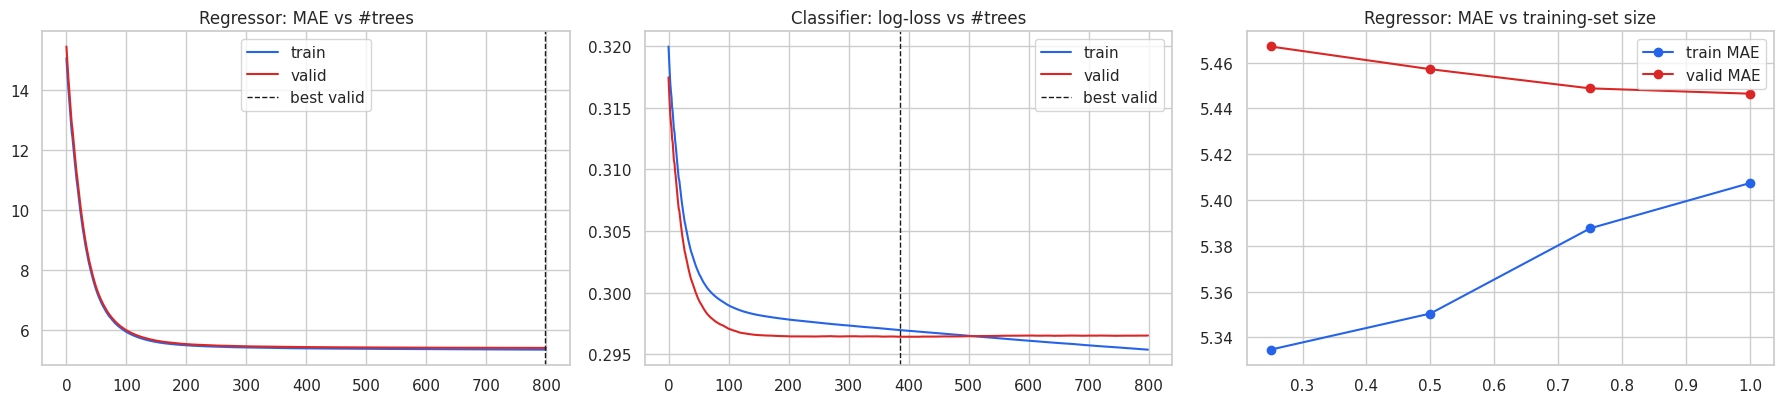

,train_frac,MAE_train,MAE_valid,PRAUC_train,PRAUC_valid
0,0.2500,5.3347,5.4670,0.2464,0.2075
1,0.5000,5.3505,5.4571,0.2370,0.2075
2,0.7500,5.3877,5.4488,0.2243,0.2085
3,1.0000,5.4074,5.4464,0.2214,0.2094


Generalisation gap (valid-train MAE) = 0.039 (0.7% of valid MAE) | noise-free floor ≈ 2.79 -> HIGH-BIAS / INFORMATION-LIMITED: train≈valid but both far above the noise-free floor -> add informative history features, not capacity


In [9]:
# %% CELL 8 — Over-/under-fitting diagnostics: learning curves (trees) and learning curves (sample size)
final_kw = dict(learning_rate=.03, n_estimators=4000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbosity=-1)
es = lambda: [lgb.early_stopping(150, verbose=False)]
curve_kw = {**final_kw, "n_estimators": 800}
mr_ = lgb.LGBMRegressor(**curve_kw, **BEST["reg"]).fit(Xtr, ytr_r, eval_set=[(Xtr, ytr_r), (Xva, yva_r)], eval_metric="l1")
mc_ = lgb.LGBMClassifier(**curve_kw, **BEST["clf"]).fit(Xtr, ytr_c, eval_set=[(Xtr, ytr_c), (Xva, yva_c)], eval_metric="binary_logloss")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for a_, m_, key, ttl in [(ax[0], mr_, "l1", "Regressor: MAE vs #trees"), (ax[1], mc_, "binary_logloss", "Classifier: log-loss vs #trees")]:
    ev_ = m_.evals_result_; k0, k1 = list(ev_)[0], list(ev_)[1]
    a_.plot(ev_[k0][key], color=PAL["blue"], label="train"); a_.plot(ev_[k1][key], color=PAL["red"], label="valid")
    a_.axvline(int(np.argmin(ev_[k1][key])), c="k", ls="--", lw=1, label="best valid"); a_.set_title(ttl); a_.legend()
fr_list = [.25, .5, .75, 1.0]; lc = []
for fr in fr_list:
    sub = (tr.timestamp >= tr.timestamp.quantile(1 - fr)).to_numpy()                # most recent fr of the TRAIN period
    kw = {**final_kw, "n_estimators": 300}
    rr = lgb.LGBMRegressor(**kw, **BEST["reg"]).fit(Xtr[sub], ytr_r[sub]); cc = lgb.LGBMClassifier(**kw, **BEST["clf"]).fit(Xtr[sub], ytr_c[sub])
    lc.append(dict(train_frac=fr, MAE_train=mean_absolute_error(ytr_r[sub], rr.predict(Xtr[sub])), MAE_valid=mean_absolute_error(yva_r, rr.predict(Xva)),
                   PRAUC_train=average_precision_score(ytr_c[sub], cc.predict_proba(Xtr[sub])[:, 1]), PRAUC_valid=average_precision_score(yva_c, cc.predict_proba(Xva)[:, 1])))
lc = pd.DataFrame(lc); ax[2].plot(lc.train_frac, lc.MAE_train, "o-", c=PAL["blue"], label="train MAE"); ax[2].plot(lc.train_frac, lc.MAE_valid, "o-", c=PAL["red"], label="valid MAE")
ax[2].set_title("Regressor: MAE vs training-set size"); ax[2].legend(); savefig("learning_curves.png"); show(lc.round(4), "RdYlGn", reverse=True)
gap_ = lc.MAE_valid.iloc[-1] - lc.MAE_train.iloc[-1]; rel = gap_/lc.MAE_valid.iloc[-1]
oracle_mae_valid = mean_absolute_error(yva_r, va.oracle_risk_mean)
verdict = ("OVER-FITTING: large train/valid gap -> more regularisation / fewer leaves" if rel > .15 else
           "HIGH-BIAS / INFORMATION-LIMITED: train≈valid but both far above the noise-free floor -> add informative history features, not capacity" if lc.MAE_train.iloc[-1] > 1.5*oracle_mae_valid and rel < .08 else
           "BALANCED: small gap and error close to the achievable floor")
print(f"Generalisation gap (valid-train MAE) = {gap_:.3f} ({rel:.1%} of valid MAE) | noise-free floor ≈ {oracle_mae_valid:.2f} -> {verdict}")

In [10]:
# %% CELL 9 — Final models: regularisation switches (monotone constraints, recency weights) chosen on VALID, then blend
MONO_BASE = ["security_score","security_score_lag1","security_score_roll6","security_score_roll24","security_score_ewm3","security_score_ewm12",
             "security_score_lag2","security_score_zmean","weather_severity","zone_activity_score","zone_activity_score_lag1",
             "zone_activity_score_ewm3","zone_activity_score_ewm12","historical_incidents_30d","historical_incidents_30d_lag1",
             "reports_last_24h","reports_last_24h_roll6","neighbor_security_lag1","neighbor_security_roll6"]
mono = [1 if nme in {"num__" + f for f in MONO_BASE} else 0 for nme in FN]       # risk should never FALL when these rise (domain prior)
print("Monotone-constrained columns:", [f for f, m_ in zip(FN, mono) if m_])
tw = pd.Series(0.5 ** (((tr.timestamp.max() - tr.timestamp).dt.total_seconds()/86400)/CFG["halflife_days"]).to_numpy())  # recency weights

def fit_gbm(kind, mono_on, decay_on, n_est=None, Xa=None, ya=None, wa=None):
    kw = {**final_kw, **BEST[kind]}
    if mono_on: kw["monotone_constraints"] = mono
    Xa = Xtr if Xa is None else Xa; ya = (ytr_r if kind == "reg" else ytr_c) if ya is None else ya
    w = (tw.to_numpy() if decay_on else None) if wa is None else wa
    m = lgb.LGBMRegressor(**kw) if kind == "reg" else lgb.LGBMClassifier(**kw)
    if n_est: return m.set_params(n_estimators=n_est).fit(Xa, ya, sample_weight=w)
    return m.fit(Xa, ya, sample_weight=w, eval_set=[(Xva, yva_r if kind == "reg" else yva_c)], callbacks=es())

combo = {}; rep = []
for kind in ("reg", "clf"):
    cand = []
    for mo in (False, True):
        for dc in (False, True):
            m_ = fit_gbm(kind, mo, dc)
            s_ = mean_absolute_error(yva_r, m_.predict(Xva)) if kind == "reg" else -average_precision_score(yva_c, m_.predict_proba(Xva)[:, 1])
            cand.append((s_, mo, dc, m_)); rep.append(dict(model=kind, monotone=mo, recency_weights=dc, valid_score=abs(s_), trees=m_.best_iteration_))
    combo[kind] = min(cand, key=lambda r: r[0])
show(pd.DataFrame(rep), "RdYlGn", reverse=False)
reg, clf = combo["reg"][3], combo["clf"][3]
print(f"Chosen -> regressor: monotone={combo['reg'][1]}, recency={combo['reg'][2]} | classifier: monotone={combo['clf'][1]}, recency={combo['clf'][2]}")
nit = lambda m: max(50, int(m.best_iteration_ or 300))

# blend GBM with the linear model (weights picked on VALID only; the data are mostly linear in the latent risk)
gv, rv = np.clip(reg.predict(Xva), 0, 100), np.clip(ridge.predict(Xva), 0, 100)
wr = float(min(np.linspace(0, 1, 11), key=lambda w_: mean_absolute_error(yva_r, w_*gv + (1-w_)*rv)))
pg, pl = clf.predict_proba(Xva)[:, 1], logit.predict_proba(Xva)[:, 1]
wc = float(max(np.linspace(0, 1, 11), key=lambda w_: average_precision_score(yva_c, w_*pg + (1-w_)*pl)))
print(f"Blend weights (GBM share): regression {wr:.1f} | classification {wc:.1f}")
blend_r = lambda X: wr*np.clip(reg.predict(X), 0, 100) + (1-wr)*np.clip(ridge.predict(X), 0, 100)
blend_c = lambda X: wc*clf.predict_proba(X)[:, 1] + (1-wc)*logit.predict_proba(X)[:, 1]

alpha = CFG["conformal_alpha"]; qkw = {**final_kw, **BEST["reg"], "n_estimators": max(200, nit(reg))}
q_lo = lgb.LGBMRegressor(objective="quantile", alpha=alpha/2, **qkw).fit(Xtr, ytr_r)
q_hi = lgb.LGBMRegressor(objective="quantile", alpha=1-alpha/2, **qkw).fit(Xtr, ytr_r)
yc = yca_r.to_numpy(); Eres = np.maximum(q_lo.predict(Xca) - yc, yc - q_hi.predict(Xca))
kq = int(np.ceil((len(Eres)+1)*(1-alpha))); Q = float(np.sort(Eres)[min(kq, len(Eres))-1])
print(f"CQR conformal correction Q = {Q:.3f}")

# calibration: choose none / Platt / isotonic by log-loss on the THRESH period (isotonic made PR-AUC worse in v4 via ties)
def logit_(p): p = np.clip(np.asarray(p, float), 1e-6, 1-1e-6); return np.log(p/(1-p))
def apply_cal(s, cal):
    if cal["kind"] == "platt": return 1/(1+np.exp(-(cal["a"]*logit_(s) + cal["b"])))
    if cal["kind"] == "isotonic": return cal["model"].predict(np.asarray(s, float))
    return np.asarray(s, float)
s_ca, s_th = blend_c(Xca), blend_c(Xth); y_th = yth_c.to_numpy()
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit_(s_ca).reshape(-1, 1), yca_c)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s_ca, yca_c)
cals = {"none": dict(kind="none"), "platt": dict(kind="platt", a=float(platt.coef_[0, 0]), b=float(platt.intercept_[0])),
        "isotonic": dict(kind="isotonic", model=iso)}
cal_scores = pd.DataFrame({k: dict(logloss=log_loss(y_th, np.clip(apply_cal(s_th, c), 1e-6, 1-1e-6)), brier=brier_score_loss(y_th, apply_cal(s_th, c)),
                                   ECE=ece(y_th, apply_cal(s_th, c)), PR_AUC=average_precision_score(y_th, apply_cal(s_th, c))) for k, c in cals.items()}).T
show(cal_scores.round(5), "RdYlGn", reverse=True); CAL = cal_scores.logloss.idxmin(); CAL_D = cals[CAL]; print("Calibrator chosen:", CAL)

Monotone-constrained columns: ['num__security_score_ewm3', 'num__security_score', 'num__weather_severity', 'num__zone_activity_score', 'num__security_score_zmean', 'num__historical_incidents_30d', 'num__neighbor_security_lag1', 'num__reports_last_24h']


,model,monotone,recency_weights,valid_score,trees
0,reg,False,False,5.3889,1601
1,reg,False,True,5.3916,1700
2,reg,True,False,5.4520,835
3,reg,True,True,5.4525,835
4,clf,False,False,0.2090,387
5,clf,False,True,0.2089,235
6,clf,True,False,0.2088,221
7,clf,True,True,0.2088,222


Chosen -> regressor: monotone=False, recency=False | classifier: monotone=False, recency=False
Blend weights (GBM share): regression 1.0 | classification 0.8
CQR conformal correction Q = 0.413


,logloss,brier,ECE,PR_AUC
none,0.3050,0.0863,0.0020,0.2146
platt,0.3050,0.0863,0.0020,0.2146
isotonic,0.3065,0.0865,0.0033,0.2055


Calibrator chosen: none


thresholds -> cost-optimal 0.095 | precision-floor 0.255 | top-10% budget 0.190 (FROZEN) | Bayes 0.091
Why budget: at a 10:1 FN:FP cost with ~10% prevalence and AUC≈0.71, the cost-optimal rule is 'alert almost everywhere'; the precision floor
then forces ~9% recall. A fixed alert BUDGET matches how dispatchers actually work (limited attention) and gives usable recall.


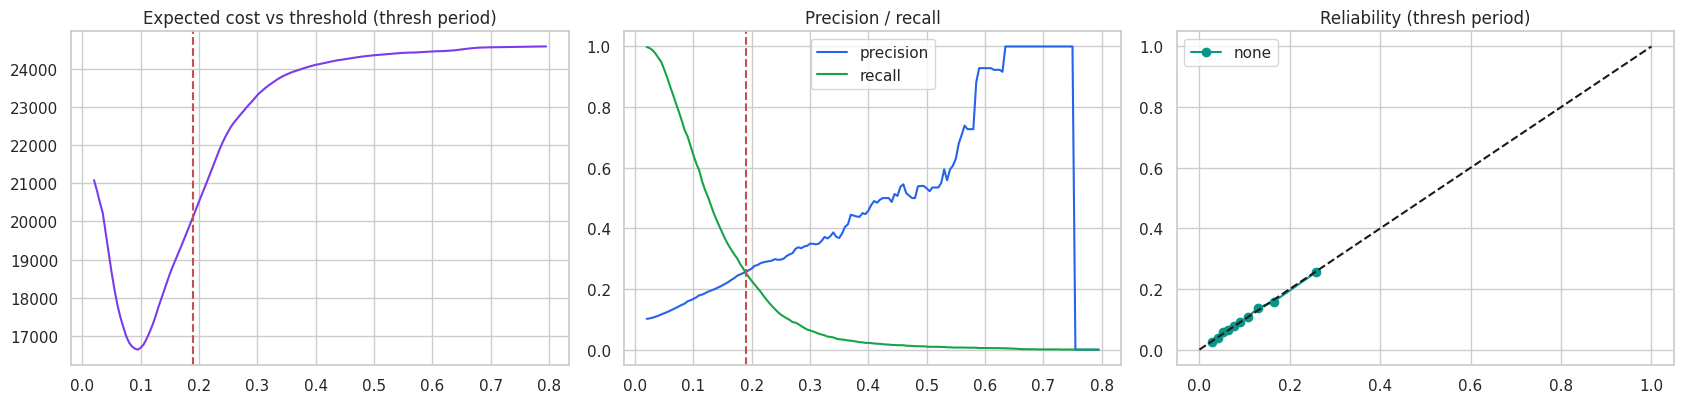

In [11]:
# %% CELL 10 — Operating point: THREE policies compared on the THRESH period, one frozen before test
p_th = apply_cal(s_th, CAL_D)
grid = np.round(np.arange(.02, .80, .005), 3); recs = []
for t_ in grid:
    pred = p_th >= t_; tp = (pred & (y_th == 1)).sum(); fp = (pred & (y_th == 0)).sum(); fn = ((~pred) & (y_th == 1)).sum()
    pr, rc = tp/max(tp+fp, 1), tp/max(tp+fn, 1)
    recs.append(dict(threshold=t_, precision=pr, recall=rc, F2=5*pr*rc/max(4*pr+rc, 1e-12), alert_rate=pred.mean(), cost=fn*CFG["cost_fn"] + fp*CFG["cost_fp"]))
tt = pd.DataFrame(recs); tt["cost_smooth"] = tt.cost.rolling(7, center=True, min_periods=1).mean()
thr_cost = float(tt.sort_values("cost_smooth").iloc[0].threshold)
okp = tt[tt.precision >= CFG["min_precision"]]; thr_floor = float((okp if len(okp) else tt).sort_values("cost_smooth").iloc[0].threshold)
thr_budget = float(np.quantile(p_th, 1 - CFG["alert_budget"]))                  # alert on the top x% most risky hours
THRESH = thr_budget                                                              # FROZEN: capacity-based policy
bayes = CFG["cost_fp"]/(CFG["cost_fp"] + CFG["cost_fn"])
print(f"thresholds -> cost-optimal {thr_cost:.3f} | precision-floor {thr_floor:.3f} | top-{CFG['alert_budget']:.0%} budget {thr_budget:.3f} (FROZEN) | Bayes {bayes:.3f}")
print("Why budget: at a 10:1 FN:FP cost with ~10% prevalence and AUC≈0.71, the cost-optimal rule is 'alert almost everywhere'; the precision floor")
print("then forces ~9% recall. A fixed alert BUDGET matches how dispatchers actually work (limited attention) and gives usable recall.")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(tt.threshold, tt.cost_smooth, c=PAL["purple"]); ax[0].axvline(THRESH, c="r", ls="--"); ax[0].set_title("Expected cost vs threshold (thresh period)")
ax[1].plot(tt.threshold, tt.precision, c=PAL["blue"], label="precision"); ax[1].plot(tt.threshold, tt.recall, c=PAL["green"], label="recall"); ax[1].axvline(THRESH, c="r", ls="--"); ax[1].legend(); ax[1].set_title("Precision / recall")
fr_, mp_ = calibration_curve(y_th, p_th, n_bins=10, strategy="quantile"); ax[2].plot(mp_, fr_, "o-", c=PAL["teal"], label=f"{CAL}"); ax[2].plot([0, 1], [0, 1], "k--"); ax[2].legend(); ax[2].set_title("Reliability (thresh period)")
savefig("threshold_calibration.png"); tt.to_csv(OUT/"threshold_table.csv", index=False)

=== REGRESSION (test) ===


,MAE,RMSE,R2
Median baseline,16.5160,19.7889,-0.0053
Naive (current security score),10.4151,13.3662,0.5414
Ridge,5.5645,6.9760,0.8751
LightGBM no-history,7.1429,9.0177,0.7912
LightGBM only,5.2892,6.6776,0.8855
FINAL (GBM + Ridge blend),5.2892,6.6776,0.8855
Oracle ceiling (noise-free truth),2.7869,3.4978,0.9686


90% CQR interval: coverage=0.899, mean width=21.95
=== CLASSIFICATION (test) ===


,PR_AUC,ROC_AUC,Brier,LogLoss,ECE
Prior,0.1108,0.5000,0.0987,0.3491,0.0126
Persistence (event_lag1),0.1247,0.5420,nan,nan,nan
Logistic,0.2592,0.7126,0.0915,0.3177,0.0026
LightGBM no-history,0.2488,0.6994,0.0922,0.3212,0.0040
LightGBM only,0.2587,0.7121,0.0915,0.3177,0.0028
Blend raw,0.2593,0.7125,0.0915,0.3176,0.0023
FINAL (blend + calibrated),0.2593,0.7125,0.0915,0.3176,0.0023
Oracle ceiling (true probability),0.2740,0.7229,0.0906,0.3143,0.0019


=== THREE OPERATING POLICIES (test) ===


,threshold,precision,recall,specificity,F2,MCC,alert_rate,cost,cost_never,cost_always
cost-optimal,0.0950,0.1784,0.7084,0.5934,0.4444,0.1909,0.4400,27732.0,44890.0,36011.0
precision-floor (v4),0.2550,0.3547,0.1931,0.9562,0.2125,0.1969,0.0603,37797.0,44890.0,36011.0
top-10% budget (FINAL),0.1899,0.2841,0.3317,0.8958,0.3209,0.2128,0.1294,33752.0,44890.0,36011.0


=== LIFT / GAINS (test) ===


,precision,recall,lift
alert_frac,,,
0.010000,0.5086,0.0459,4.5890
0.020000,0.4469,0.0806,4.0321
0.050000,0.3714,0.1675,3.3504
0.100000,0.3047,0.2749,2.7489
0.200000,0.2438,0.4400,2.1998
0.300000,0.2096,0.5674,1.8913


95% CI (zone-cluster ∪ day-block bootstrap) [MAE, PR-AUC, precision, recall]:
 lower [5.2098 0.2353 0.2697 0.2871] 
 upper [5.3569 0.2853 0.3019 0.3839]
   zone-only CI lower/upper: [5.2098 0.2353 0.2697 0.2871] [5.3569 0.2853 0.3019 0.3839] 
   day-block CI lower/upper: [5.23   0.2415 0.272  0.2963] [5.3555 0.2755 0.2971 0.3599]


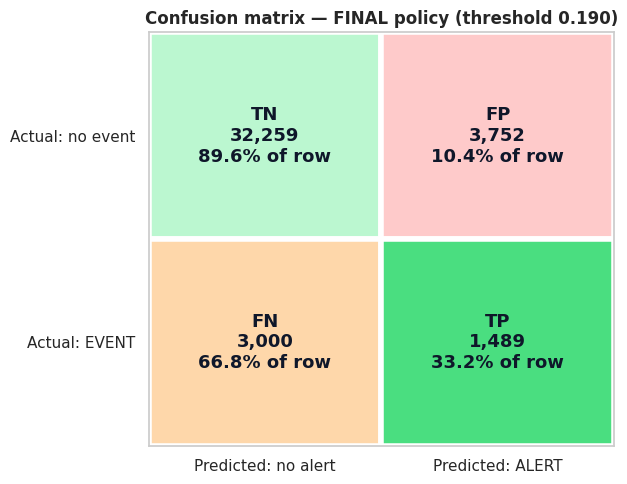

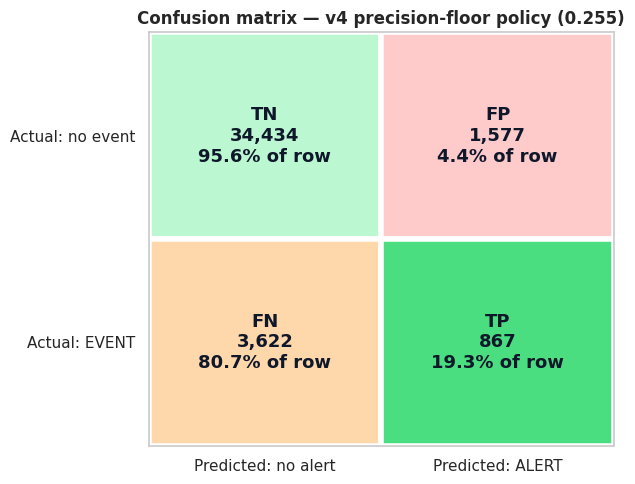

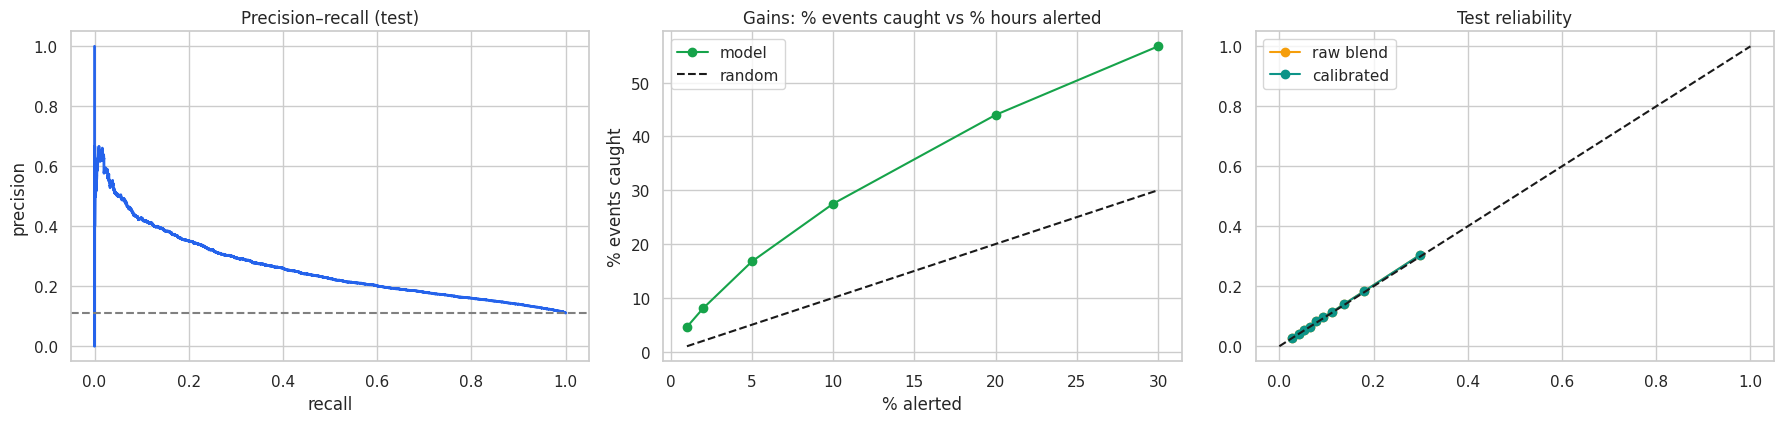

In [12]:
# %% CELL 11 — Held-out TEST evaluation with zone-cluster AND day-block bootstrap
te = te.copy(); Xte = T_(te)
te["pred_risk"] = np.clip(blend_r(Xte), 0, 100)
lo_, hi_ = np.clip(q_lo.predict(Xte) - Q, 0, 100), np.clip(q_hi.predict(Xte) + Q, 0, 100)
te["risk_lo"], te["risk_hi"] = np.minimum(lo_, te.pred_risk), np.maximum(hi_, te.pred_risk)
te["p_raw"] = blend_c(Xte); te["p_cal"] = apply_cal(te.p_raw, CAL_D); te["alert_model"] = (te.p_cal >= THRESH).astype(int)
yt, y_r, p = yte_c.to_numpy(), yte_r.to_numpy(), te.p_cal.to_numpy()

INST_NUM = ["security_score", "historical_incidents_30d", "reports_last_24h", "zone_activity_score", "weather_severity", "source_reliability", "road_condition_score"]
pre_nl, FN_nl, T_nl = design(INST_NUM, CAT_FINAL); Xtr_nl, Xte_nl = T_nl(tr), T_nl(te)
abl_r = lgb.LGBMRegressor(**{**final_kw, **BEST["reg"], "n_estimators": nit(reg)}).fit(Xtr_nl, ytr_r)
abl_c = lgb.LGBMClassifier(**{**final_kw, **BEST["clf"], "n_estimators": nit(clf)}).fit(Xtr_nl, ytr_c)
te["pred_risk_nolag"] = np.clip(abl_r.predict(Xte_nl), 0, 100); te["p_nolag"] = abl_c.predict_proba(Xte_nl)[:, 1]

def reg_m(pred): return dict(MAE=mean_absolute_error(y_r, pred), RMSE=np.sqrt(mean_squared_error(y_r, pred)), R2=r2_score(y_r, pred))
reg_tbl = pd.DataFrame({
 "Median baseline": reg_m(base_reg_dummy.predict(Xte)),
 "Naive (current security score)": reg_m(np.clip(te.security_score.fillna(tr.security_score.median()), 0, 100)),
 "Ridge": reg_m(np.clip(ridge.predict(Xte), 0, 100)), "LightGBM no-history": reg_m(te.pred_risk_nolag),
 "LightGBM only": reg_m(np.clip(reg.predict(Xte), 0, 100)),
 "FINAL (GBM + Ridge blend)": reg_m(te.pred_risk), "Oracle ceiling (noise-free truth)": reg_m(te.oracle_risk_mean)}).T
cover = ((y_r >= te.risk_lo) & (y_r <= te.risk_hi)).mean(); width = (te.risk_hi - te.risk_lo).mean()

def clf_row(s, prob=True):
    d = dict(PR_AUC=average_precision_score(yt, s), ROC_AUC=roc_auc_score(yt, s))
    if prob: sc = np.clip(s, 1e-6, 1-1e-6); d.update(Brier=brier_score_loss(yt, sc), LogLoss=log_loss(yt, sc), ECE=ece(yt, sc))
    return d
clf_tbl = pd.DataFrame({
 "Prior": clf_row(np.full(len(te), ytr_c.mean())), "Persistence (event_lag1)": clf_row(te.event_lag1.fillna(0).to_numpy(), False),
 "Logistic": clf_row(logit.predict_proba(Xte)[:, 1]), "LightGBM no-history": clf_row(te.p_nolag.to_numpy()),
 "LightGBM only": clf_row(clf.predict_proba(Xte)[:, 1]), "Blend raw": clf_row(te.p_raw.to_numpy()),
 "FINAL (blend + calibrated)": clf_row(p), "Oracle ceiling (true probability)": clf_row(te.oracle_event_prob.to_numpy())}).T
cost = lambda pred: int(((pred == 0) & (yt == 1)).sum()*CFG["cost_fn"] + ((pred == 1) & (yt == 0)).sum()*CFG["cost_fp"])
pol_rows = {}
for nm_, th_ in [("cost-optimal", thr_cost), ("precision-floor (v4)", thr_floor), (f"top-{CFG['alert_budget']:.0%} budget (FINAL)", thr_budget)]:
    aa = (p >= th_).astype(int)
    pol_rows[nm_] = dict(threshold=th_, precision=precision_score(yt, aa, zero_division=0), recall=recall_score(yt, aa, zero_division=0),
        specificity=recall_score(1-yt, 1-aa, zero_division=0), F2=fbeta_score(yt, aa, beta=2, zero_division=0), MCC=matthews_corrcoef(yt, aa),
        alert_rate=aa.mean(), cost=cost(aa), cost_never=cost(np.zeros_like(aa)), cost_always=cost(np.ones_like(aa)))
pol_tbl = pd.DataFrame(pol_rows).T
a_ = te.alert_model.to_numpy(); thr_m = pol_rows[f"top-{CFG['alert_budget']:.0%} budget (FINAL)"]
lift_tbl = pd.DataFrame([topk_stats(yt, p, f) for f in (.01, .02, .05, .10, .20, .30)]).set_index("alert_frac")

zid = te.zone_id.to_numpy(); day_id = te.timestamp.dt.floor("D").astype(str).to_numpy(); pr_ = te.pred_risk.to_numpy()
stat_fn = lambda i: [mean_absolute_error(y_r[i], pr_[i]), average_precision_score(yt[i], p[i]),
                     precision_score(yt[i], a_[i], zero_division=0), recall_score(yt[i], a_[i], zero_division=0)]
ci_z = cluster_bootstrap(zid, stat_fn, n=CFG["n_boot"]); ci_d = cluster_bootstrap(day_id, stat_fn, n=CFG["n_boot"], seed=SEED+1)
ci = np.vstack([np.minimum(ci_z[0], ci_d[0]), np.maximum(ci_z[1], ci_d[1])])      # conservative: widest of the two

print("=== REGRESSION (test) ==="); show(reg_tbl.round(4), "RdYlGn", reverse=True); print(f"90% CQR interval: coverage={cover:.3f}, mean width={width:.2f}")
print("=== CLASSIFICATION (test) ==="); show(clf_tbl.round(4), "RdYlGn")
print("=== THREE OPERATING POLICIES (test) ==="); display(pol_tbl.round(4)); print("=== LIFT / GAINS (test) ==="); show(lift_tbl.round(4), "YlGn")
print("95% CI (zone-cluster ∪ day-block bootstrap) [MAE, PR-AUC, precision, recall]:\n lower", ci[0].round(4), "\n upper", ci[1].round(4))
print("   zone-only CI lower/upper:", ci_z[0].round(4), ci_z[1].round(4), "\n   day-block CI lower/upper:", ci_d[0].round(4), ci_d[1].round(4))

pretty_confusion(yt, a_, f"Confusion matrix — FINAL policy (threshold {THRESH:.3f})", "test_confusion_final.png")
pretty_confusion(yt, (p >= thr_floor).astype(int), f"Confusion matrix — v4 precision-floor policy ({thr_floor:.3f})", "test_confusion_v4.png")
prc, rcc, _ = precision_recall_curve(yt, p); fr1, mp1 = calibration_curve(yt, te.p_raw, n_bins=10, strategy="quantile"); fr2, mp2 = calibration_curve(yt, p, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
ax[0].plot(rcc, prc, c=PAL["blue"], lw=2); ax[0].axhline(yt.mean(), c="gray", ls="--"); ax[0].set(title="Precision–recall (test)", xlabel="recall", ylabel="precision")
ax[1].plot(lift_tbl.index*100, lift_tbl.recall*100, "o-", c=PAL["green"], label="model"); ax[1].plot(lift_tbl.index*100, lift_tbl.index*100, "k--", label="random"); ax[1].legend(); ax[1].set(title="Gains: % events caught vs % hours alerted", xlabel="% alerted", ylabel="% events caught")
ax[2].plot(mp1, fr1, "o-", c=PAL["amber"], label="raw blend"); ax[2].plot(mp2, fr2, "o-", c=PAL["teal"], label="calibrated"); ax[2].plot([0, 1], [0, 1], "k--"); ax[2].legend(); ax[2].set_title("Test reliability")
savefig("test_pr_gains_calibration.png")
te[["zone_id", "timestamp", REG_T, "pred_risk", "risk_lo", "risk_hi", CLF_T, "p_cal", "alert_model"]].to_csv(OUT/"heldout_predictions.csv", index=False)

=== RESIDUAL DEPENDENCE (compare models; the RAW target had lag-1 ACF 0.80 / DW 0.40) ===


,mean_lag1_ACF,mean_DW,pct_zones_LjungBox_p_lt_05,MoransI,Moran_p
FINAL (history + smoothing features),0.3671,1.2127,0.8167,0.0854,0.0060
no-history ablation,0.0915,1.5678,0.2467,0.3931,0.0020
naive (current score),0.1550,1.4851,0.4633,0.7988,0.0020


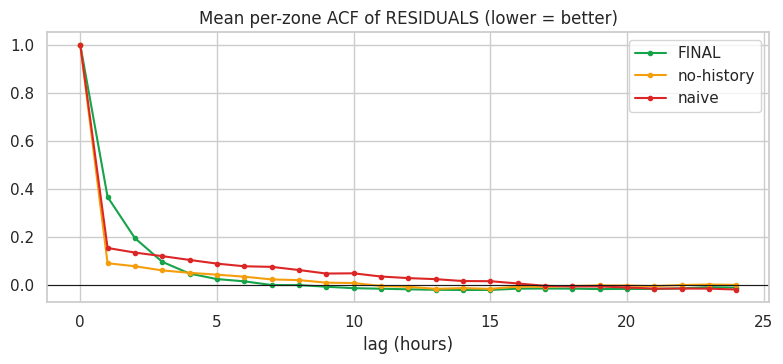

HOW TO READ THIS: (1) Moran's I of residuals ≈ 0 and p>0.05 => spatial dependence is absorbed (the naive baseline keeps it).
(2) Residual lag-1 ACF will NOT be ~0 for a model that estimates a persistent latent state from noisy proxies: the estimation error
    is itself persistent (smoothing makes errors drift slowly). That is not leakage and not a bug; it means (a) report CIs with the
    day-block/zone bootstrap (done), and (b) the only way to cut it further is a causally-available delayed measurement of the truth.
(3) Judge success by LOWER MAE/RMSE on the purged test block, not by white-noise residuals.


In [13]:
# %% CELL 12 — Residual autocorrelation + spatial dependence of the MODEL ERRORS (the real test of "autocorrelation fixed")
def zone_diag(res):
    rv = np.asarray(res); out = []
    for z, idx in te.groupby("zone_id", sort=False).indices.items():
        r = rv[idx]; lbp = acorr_ljungbox(r, lags=[24], return_df=True)["lb_pvalue"].iloc[0]
        out.append((acf(r, nlags=24, fft=True)[1], durbin_watson(r), lbp))
    o = np.array(out); return dict(mean_lag1_ACF=o[:, 0].mean(), mean_DW=o[:, 1].mean(), pct_zones_LjungBox_p_lt_05=(o[:, 2] < .05).mean())
res_full, res_nolag, res_naive = (te[REG_T] - te.pred_risk), (te[REG_T] - te.pred_risk_nolag), (te[REG_T] - te.security_score.fillna(50).clip(0, 100))
zm = lambda r: te.assign(r=r).groupby("zone_id")["r"].mean().reindex(zones.zone_id).to_numpy()
diag = pd.DataFrame({"FINAL (history + smoothing features)": {**zone_diag(res_full), **dict(zip(["MoransI", "Moran_p"], morans_i(zm(res_full), W)))},
                     "no-history ablation": {**zone_diag(res_nolag), **dict(zip(["MoransI", "Moran_p"], morans_i(zm(res_nolag), W)))},
                     "naive (current score)": {**zone_diag(res_naive), **dict(zip(["MoransI", "Moran_p"], morans_i(zm(res_naive), W)))}}).T
print("=== RESIDUAL DEPENDENCE (compare models; the RAW target had lag-1 ACF 0.80 / DW 0.40) ==="); show(diag.round(4), "RdYlGn", reverse=True)
fig, ax = plt.subplots(figsize=(8, 3.8))
for res_, lab_, col_ in [(res_full, "FINAL", PAL["green"]), (res_nolag, "no-history", PAL["amber"]), (res_naive, "naive", PAL["red"])]:
    ax.plot(np.mean([acf(np.asarray(res_)[idx], nlags=24, fft=True) for idx in te.groupby("zone_id", sort=False).indices.values()], axis=0), "o-", ms=3, c=col_, label=lab_)
ax.axhline(0, c="k", lw=.8); ax.set(title="Mean per-zone ACF of RESIDUALS (lower = better)", xlabel="lag (hours)"); ax.legend(); savefig("residual_acf.png")
print("HOW TO READ THIS: (1) Moran's I of residuals ≈ 0 and p>0.05 => spatial dependence is absorbed (the naive baseline keeps it).")
print("(2) Residual lag-1 ACF will NOT be ~0 for a model that estimates a persistent latent state from noisy proxies: the estimation error")
print("    is itself persistent (smoothing makes errors drift slowly). That is not leakage and not a bug; it means (a) report CIs with the")
print("    day-block/zone bootstrap (done), and (b) the only way to cut it further is a causally-available delayed measurement of the truth.")
print("(3) Judge success by LOWER MAE/RMSE on the purged test block, not by white-noise residuals.")

--- slice: nearest_hub


,rows,prevalence,MAE,PR_AUC,precision,recall,ECE,PI_coverage
group,,,,,,,,
Adama,4320,0.0730,5.5130,0.1860,0.3620,0.0920,0.0070,0.8970
Addis Ababa,3780,0.0960,5.2370,0.2420,0.2960,0.2950,0.0130,0.9110
Awash,3510,0.1080,5.3320,0.2190,0.2490,0.2820,0.0110,0.8920
Dessie,3510,0.0980,5.3500,0.2270,0.2760,0.2580,0.0100,0.8980
Dire Dawa,2430,0.0960,5.3360,0.2170,0.3130,0.2020,0.0140,0.9070
Djibouti Port,4320,0.0680,5.4910,0.1540,0.2350,0.1200,0.0060,0.8950
Galafi,5130,0.2100,4.6550,0.3820,0.3110,0.6770,0.0140,0.8940
Mille,4995,0.0970,5.4560,0.1930,0.2310,0.1660,0.0020,0.9040
Modjo,4185,0.0790,5.5840,0.1380,0.1940,0.0730,0.0090,0.9000


--- slice: weather_severity


,rows,prevalence,MAE,PR_AUC,precision,recall,ECE,PI_coverage
group,,,,,,,,
0,27823,0.0910,5.3760,0.2000,0.2530,0.1860,0.0020,0.9020
1,6606,0.1100,5.4620,0.2050,0.2570,0.2610,0.0040,0.8990
2,1045,0.1190,5.3550,0.3050,0.2750,0.4440,0.0240,0.9000
3,5026,0.2220,4.5660,0.3820,0.3170,0.6960,0.0180,0.8840


--- slice: source_type


,rows,prevalence,MAE,PR_AUC,precision,recall,ECE,PI_coverage
group,,,,,,,,
government_advisory,14784,0.1140,5.2560,0.2610,0.2750,0.3410,0.0040,0.8990
unverified_crowdsourced,4411,0.1140,5.3220,0.2680,0.2910,0.3470,0.0060,0.9010
verified_crowdsourced,21305,0.1080,5.3060,0.2580,0.2900,0.3210,0.0020,0.8990


=== DRIFT train->test === score PSI: 0.0163 | prevalence 0.098 -> 0.111


,feature,PSI,flag
2,weather_severity,0.1854,watch
7,neighbor_security_lag1,0.0127,ok
4,security_score_zmean,0.0072,ok
0,security_score_ewm3,0.0069,ok
5,hour_sin,0.0053,ok
1,security_score,0.0050,ok
9,historical_incidents_30d_roll6,0.0030,ok
3,zone_activity_score,0.0028,ok
6,historical_incidents_30d,0.0011,ok
8,reports_last_24h,0.0009,ok


=== NEW-ZONE GENERALISATION (unseen zones, future period) ===
 PR-AUC  main: 0.2304 | zone-blind: 0.2301
 MAE     main: 5.394 | zone-blind: 5.401


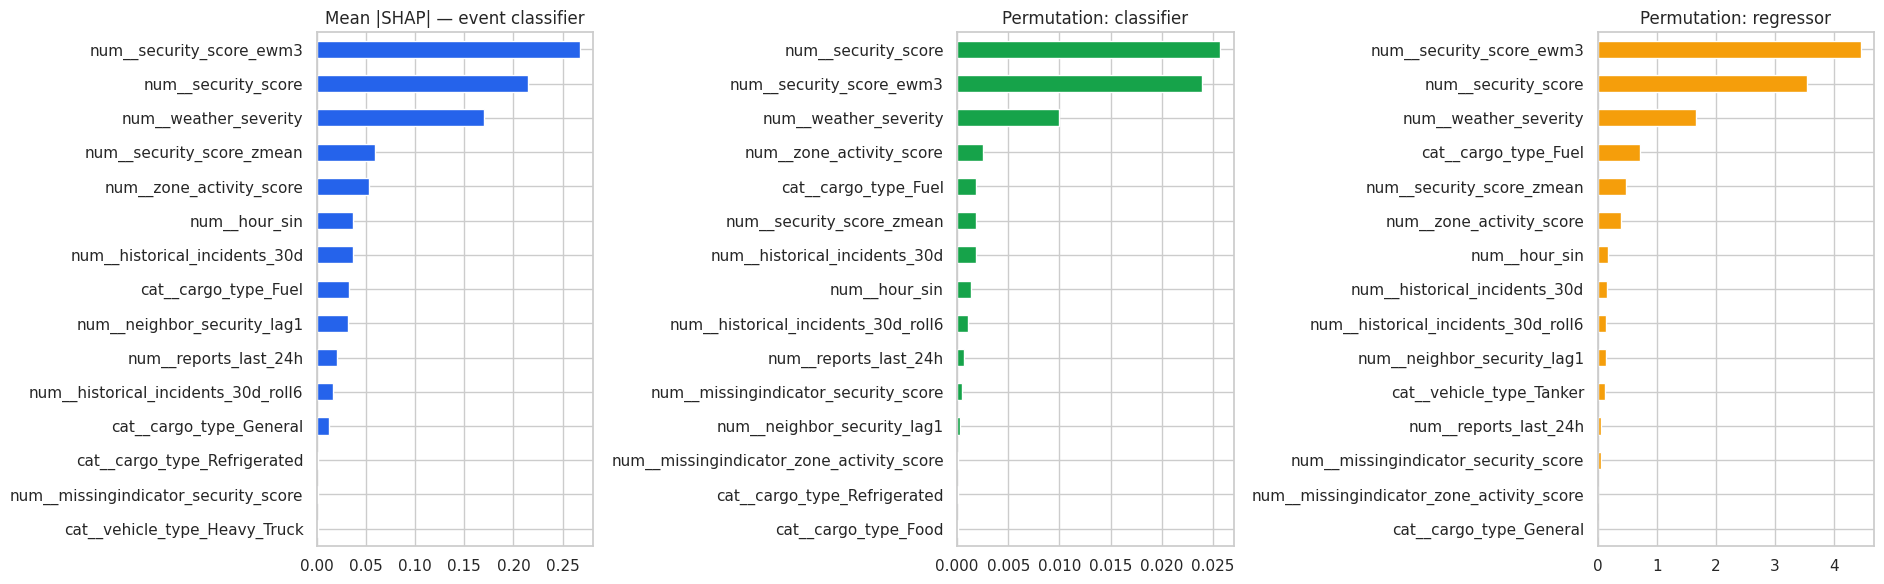

In [14]:
# %% CELL 13 — Slices, drift (PSI), new-zone generalisation, explainability
def slice_report(col):
    out = []
    for kk, d in te.groupby(col):
        yy, pp, aa = d[CLF_T].to_numpy(), d.p_cal.to_numpy(), d.alert_model.to_numpy()
        out.append(dict(group=kk, rows=len(d), prevalence=yy.mean(), MAE=mean_absolute_error(d[REG_T], d.pred_risk),
            PR_AUC=average_precision_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan, precision=precision_score(yy, aa, zero_division=0),
            recall=recall_score(yy, aa, zero_division=0), ECE=ece(yy, pp), PI_coverage=((d[REG_T] >= d.risk_lo) & (d[REG_T] <= d.risk_hi)).mean()))
    return pd.DataFrame(out).round(3)
for c in ["nearest_hub", "weather_severity", "source_type"]: print(f"--- slice: {c}"); show(slice_report(c).set_index("group"), "YlGnBu")

drift = pd.DataFrame({"feature": FEATURES_NUM, "PSI": [psi(tr[c], te[c]) for c in FEATURES_NUM]}).sort_values("PSI", ascending=False)
drift["flag"] = np.where(drift.PSI > .25, "ACTION", np.where(drift.PSI > .10, "watch", "ok"))
print("=== DRIFT train->test === score PSI:", round(psi(clf.predict_proba(Xtr)[:, 1], clf.predict_proba(Xte)[:, 1]), 4), "| prevalence", round(tr[CLF_T].mean(), 3), "->", round(te[CLF_T].mean(), 3))
display(drift.round(4)); drift.to_csv(OUT/"psi_drift.csv", index=False)

hold = set(np.random.default_rng(SEED + 7).choice(zones.zone_id, int(.2*Z), replace=False))
mtr, mte = (~tr.zone_id.isin(hold)).to_numpy(), te.zone_id.isin(hold).to_numpy()
sp_c = lgb.LGBMClassifier(**{**final_kw, **BEST["clf"], "n_estimators": nit(clf)}).fit(Xtr[mtr], ytr_c[mtr])
sp_r = lgb.LGBMRegressor(**{**final_kw, **BEST["reg"], "n_estimators": nit(reg)}).fit(Xtr[mtr], ytr_r[mtr])
print("=== NEW-ZONE GENERALISATION (unseen zones, future period) ===")
print(" PR-AUC  main:", round(average_precision_score(yt[mte], te.p_raw[mte]), 4), "| zone-blind:", round(average_precision_score(yt[mte], sp_c.predict_proba(Xte[mte])[:, 1]), 4))
print(" MAE     main:", round(mean_absolute_error(y_r[mte], te.pred_risk[mte]), 3), "| zone-blind:", round(mean_absolute_error(y_r[mte], np.clip(sp_r.predict(Xte[mte]), 0, 100)), 3))

samp = Xte.sample(min(5000, len(Xte)), random_state=SEED); contrib = clf.booster_.predict(samp, pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(contrib).mean(0), index=FN).sort_values(ascending=False)
vs2 = Xva.sample(min(15000, len(Xva)), random_state=SEED)
pi_c2 = permutation_importance(clf, vs2, yva_c.loc[vs2.index], scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=1)
pi_r2 = permutation_importance(reg, vs2, yva_r.loc[vs2.index], scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=1)
pim = pd.DataFrame({"perm_clf_PRAUC_drop": pi_c2.importances_mean, "perm_reg_MAE_increase": pi_r2.importances_mean}, index=FN)
fig, ax = plt.subplots(1, 3, figsize=(19, 6))
shap_imp.head(15)[::-1].plot.barh(ax=ax[0], color=PAL["blue"]); ax[0].set_title("Mean |SHAP| — event classifier")
pim.perm_clf_PRAUC_drop.sort_values().tail(15).plot.barh(ax=ax[1], color=PAL["green"]); ax[1].set_title("Permutation: classifier")
pim.perm_reg_MAE_increase.sort_values().tail(15).plot.barh(ax=ax[2], color=PAL["amber"]); ax[2].set_title("Permutation: regressor")
savefig("feature_importance.png"); pim.sort_values("perm_clf_PRAUC_drop", ascending=False).to_csv(OUT/"permutation_importance.csv")

In [15]:
# %% CELL 14 — Alert tiers, cool-down, policy comparison
te["gate_pass"] = ((te.report_verified == 1) & (te.active_advisory == 1) & (te.source_type != "unverified_crowdsourced")).astype(int)
te["tier"] = np.select([(te.alert_model == 1) & (te.gate_pass == 1), te.alert_model == 1], ["PUSH", "WATCH"], "NONE")
te["push_raw"] = (te.tier == "PUSH").astype(int); te["gate_only"] = te.gate_pass

def apply_cooldown(prob, alert, hours, delta):
    out = np.zeros(len(alert), int); last_t, last_p = -10**9, 0.0
    for i, (a, pr) in enumerate(zip(alert, prob)):
        if a and (i - last_t > hours or pr - last_p >= delta): out[i] = 1; last_t, last_p = i, pr
    return out
pc = np.zeros(len(te), int); pv, pr_raw = te.p_cal.to_numpy(), te.push_raw.to_numpy()
for z, idx in te.groupby("zone_id", sort=False).indices.items():
    pc[idx] = apply_cooldown(pv[idx], pr_raw[idx], CFG["cooldown_hours"], CFG["cooldown_delta"])
te["push"] = pc

def episode_detect(col, lead=3):
    a, e = te[col].to_numpy(), te[CLF_T].to_numpy(); hit = tot = 0
    for z, idx in te.groupby("zone_id", sort=False).indices.items():
        ez, az = e[idx], a[idx]
        for s in np.flatnonzero((ez == 1) & (np.r_[0, ez[:-1]] == 0)): tot += 1; hit += int(az[max(0, s-lead):s+1].max() > 0)
    return hit/max(tot, 1), tot
days = te.timestamp.nunique()/24
def policy_row(name, col):
    a = te[col].to_numpy(); tp = ((a == 1) & (yt == 1)).sum(); fp = ((a == 1) & (yt == 0)).sum(); det, tot = episode_detect(col)
    return dict(policy=name, alerts_per_zone_day=a.sum()/(Z*days), precision=tp/max(tp+fp, 1), hour_recall=tp/max(yt.sum(), 1), episode_detection=det, episodes=tot)
policy = pd.DataFrame([policy_row("Gate-only rule (v1-style)", "gate_only"), policy_row("Model alert (PUSH+WATCH)", "alert_model"),
                       policy_row("PUSH (model + verified gate)", "push_raw"), policy_row("PUSH + cooldown (production)", "push")]).round(4)
show(policy.set_index("policy"), "YlGnBu"); policy.to_csv(OUT/"alert_policy_comparison.csv", index=False)
print(te.tier.value_counts(normalize=True).round(4).to_dict(), "| WATCH items go to human review, not push notification.")

,alerts_per_zone_day,precision,hour_recall,episode_detection,episodes
policy,,,,,
Gate-only rule (v1-style),7.5046,0.1121,0.3163,0.7143,3661
Model alert (PUSH+WATCH),3.1058,0.2841,0.3317,0.3622,3661
PUSH (model + verified gate),0.9973,0.2846,0.1067,0.2163,3661
PUSH + cooldown (production),0.5665,0.2762,0.0588,0.1874,3661


{'NONE': 0.8706, 'WATCH': 0.0879, 'PUSH': 0.0416} | WATCH items go to human review, not push notification.


,no_path_pct,mean_minutes,detour_pct,mean_node_risk,mean_max_risk,pct_routes_touching_blocked
strategy,,,,,,
fastest,0.0000,578.8400,0.0000,61.2200,83.3300,61.5000
risk_aware,0.0000,581.5100,0.5000,59.0600,80.3300,61.5000
hard_avoid,39.0000,553.1000,2.2300,59.8300,82.1100,0.0000


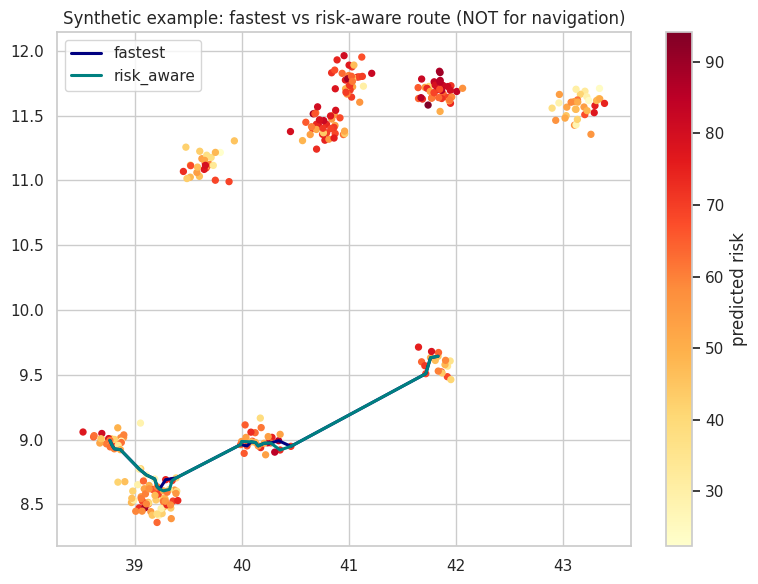

Caveat: risk exposure uses the model's own predictions; this is a design check, not proof of safety.


In [16]:
# %% CELL 15 — Rerouting on a connected synthetic graph (illustrative, NOT a road network)
coords = zones[["latitude", "longitude"]].to_numpy(); dm = cdist(coords, coords); np.fill_diagonal(dm, np.inf)
G = nx.Graph(); G.add_nodes_from(zones.zone_id); idx_of = {z: i for i, z in enumerate(zones.zone_id)}
def add_edge(i, j):
    km = max(float(haversine_km(*coords[i], *coords[j])), .2)
    G.add_edge(zones.zone_id[i], zones.zone_id[j], distance_km=km, travel_minutes=km/45*60)
for i, row in enumerate(np.argsort(dm, axis=1)[:, :4]):
    for j in row: add_edge(i, int(j))
while not nx.is_connected(G):
    comps = sorted(nx.connected_components(G), key=len); A = [idx_of[z] for z in comps[0]]
    B = [idx_of[z] for z in G.nodes if z not in comps[0]]; sub = dm[np.ix_(A, B)]
    ia, ib = np.unravel_index(np.argmin(sub), sub.shape); add_edge(A[ia], B[ib])

snap = te[te.timestamp == te.timestamp.max()].set_index("zone_id")
risk_node = snap.pred_risk.to_dict(); blocked = set(snap.index[snap.push_raw == 1])
for u_, v_, d in G.edges(data=True):
    d["risk_cost"] = d["travel_minutes"]*(1 + CFG["lambda_risk"]*.5*(risk_node[u_] + risk_node[v_])/100)
def route(o, d, how):
    if how == "hard_avoid":
        Hh = G.copy(); Hh.remove_nodes_from(blocked - {o, d})
        try: return nx.shortest_path(Hh, o, d, weight="travel_minutes")
        except (nx.NetworkXNoPath, nx.NodeNotFound): return None
    return nx.shortest_path(G, o, d, weight="travel_minutes" if how == "fastest" else "risk_cost")
def pstats(path):
    e = [G[u_][v_] for u_, v_ in zip(path[:-1], path[1:])]
    return dict(minutes=sum(x["travel_minutes"] for x in e), mean_risk=np.mean([risk_node[z] for z in path]),
                max_risk=max(risk_node[z] for z in path), blocked_hits=sum(z in blocked for z in path[1:-1]))
r2g = np.random.default_rng(SEED + 11); ids = zones.zone_id.to_numpy(); hub_of = zones.set_index("zone_id").nearest_hub; od = []
while len(od) < 200:
    o, d = r2g.choice(ids, 2, replace=False)
    if hub_of[o] == hub_of[d]: continue
    row = {"o": o, "d": d}
    for how in ("fastest", "risk_aware", "hard_avoid"):
        pth = route(o, d, how); row[how] = pstats(pth) if pth else None; row[how + "_path"] = pth
    od.append(row)
summ = []
for how in ("fastest", "risk_aware", "hard_avoid"):
    okr = [r for r in od if r[how] is not None and r["fastest"] is not None]
    summ.append(dict(strategy=how, no_path_pct=100*(1-len(okr)/len(od)), mean_minutes=np.mean([r[how]["minutes"] for r in okr]),
        detour_pct=np.mean([100*(r[how]["minutes"]/r["fastest"]["minutes"]-1) for r in okr]), mean_node_risk=np.mean([r[how]["mean_risk"] for r in okr]),
        mean_max_risk=np.mean([r[how]["max_risk"] for r in okr]), pct_routes_touching_blocked=100*np.mean([r[how]["blocked_hits"] > 0 for r in okr])))
show(pd.DataFrame(summ).set_index("strategy").round(2), "YlOrRd"); pd.DataFrame(summ).to_csv(OUT/"rerouting_comparison.csv", index=False)
ex = next((r for r in od if r["risk_aware_path"] and r["risk_aware_path"] != r["fastest_path"]), od[0])
zz = zones.set_index("zone_id"); fig, ax = plt.subplots(figsize=(8, 6))
scat = ax.scatter(zones.longitude, zones.latitude, c=[risk_node[z] for z in zones.zone_id], cmap="YlOrRd", s=18); plt.colorbar(scat, label="predicted risk")
for key, colr in (("fastest_path", "navy"), ("risk_aware_path", "teal")):
    ax.plot(zz.loc[ex[key]].longitude, zz.loc[ex[key]].latitude, color=colr, lw=2.2, label=key.replace("_path", ""))
ax.legend(); ax.set_title("Synthetic example: fastest vs risk-aware route (NOT for navigation)"); savefig("reroute_example.png")
print("Caveat: risk exposure uses the model's own predictions; this is a design check, not proof of safety.")

In [17]:
# %% CELL 16 — Bundle, inference module (parity-tested), model card, manifest, ZIP
LIMITATIONS = [
 "All data and labels are synthetic; metrics do not establish real-world conflict-prediction accuracy.",
 "Oracle ceilings are known only because the generator is known; real data has no such reference.",
 "Feature selection, blend weights and regularisation switches used the VALID period (also used for early stopping); calibration, threshold and test periods were untouched.",
 "Contemporaneous features (current security score etc.) assume they are available at prediction time (nowcasting); verify in production.",
 "Monotone constraints encode a domain prior (higher indicators -> higher risk); validate the direction on real data.",
 "Bootstrap CIs cover zone and day dependence separately (widest taken); they do not model hub-level weather shared across zones and days jointly.",
 "Coordinates and route graph are illustrative, not a real road network; do not use for navigation.",
 "Production needs authenticated advisories, expiry/audit workflows, real road geometry, shadow-mode validation, drift monitoring and human review of WATCH-tier items."]
bundle = dict(preprocessor=pre, risk_regressor=reg, ridge=ridge, w_reg=wr, risk_classifier=clf, logit=logit, w_clf=wc, calibrator=CAL_D,
              q_lo=q_lo, q_hi=q_hi, conformal_Q=Q, threshold=THRESH, features=FEATURES, features_num=FEATURES_NUM, features_cat=CAT_FINAL,
              encoded_feature_names=FN, seed=SEED, synthetic_data=True, split="purged temporal", limitations=LIMITATIONS)
joblib.dump(bundle, OUT/"fr08_bundle.joblib")

INFER_CODE = '''
import joblib, numpy as np, pandas as pd
def load_bundle(path): return joblib.load(path)
def logit_(p): p = np.clip(np.asarray(p, float), 1e-6, 1-1e-6); return np.log(p/(1-p))
def apply_cal(s, cal):
    if cal["kind"] == "platt": return 1/(1+np.exp(-(cal["a"]*logit_(s) + cal["b"])))
    if cal["kind"] == "isotonic": return cal["model"].predict(np.asarray(s, float))
    return np.asarray(s, float)
def score_batch(raw, b):
    need = list(dict.fromkeys(b["features"] + ["report_verified", "active_advisory", "source_type"]))
    missing = [c for c in need if c not in raw.columns]
    if missing: raise ValueError(f"Missing columns: {missing}")
    X = pd.DataFrame(b["preprocessor"].transform(raw[b["features"]]), columns=b["encoded_feature_names"], index=raw.index)
    risk = b["w_reg"]*np.clip(b["risk_regressor"].predict(X), 0, 100) + (1-b["w_reg"])*np.clip(b["ridge"].predict(X), 0, 100)
    lo = np.clip(b["q_lo"].predict(X) - b["conformal_Q"], 0, 100); hi = np.clip(b["q_hi"].predict(X) + b["conformal_Q"], 0, 100)
    s = b["w_clf"]*b["risk_classifier"].predict_proba(X)[:, 1] + (1-b["w_clf"])*b["logit"].predict_proba(X)[:, 1]
    p = apply_cal(s, b["calibrator"]); alert = p >= b["threshold"]
    gate = ((raw["report_verified"] == 1) & (raw["active_advisory"] == 1) & (raw["source_type"] != "unverified_crowdsourced")).to_numpy()
    tier = np.where(alert & gate, "PUSH", np.where(alert, "WATCH", "NONE"))
    return pd.DataFrame({"risk_score": risk, "risk_lo": np.minimum(lo, risk), "risk_hi": np.maximum(hi, risk),
        "event_probability": p, "model_alert": alert.astype(int), "gate_pass": gate.astype(int), "tier": tier}, index=raw.index)
'''
(OUT/"fr08_inference.py").write_text(INFER_CODE); exec(INFER_CODE)
chk = score_batch(te.head(300), bundle)
assert np.allclose(chk.risk_score, te.pred_risk.head(300), atol=1e-6) and np.allclose(chk.event_probability, te.p_cal.head(300), atol=1e-9)
assert (chk.tier.to_numpy() == te.tier.head(300).to_numpy()).all(); print("Parity test passed ✓")
try: score_batch(te.head(3).drop(columns=[FEATURES[0]]), bundle)
except ValueError as e: print("Schema guard works ✓ ->", e)

def jd(o):
    conv = lambda x: x.tolist() if isinstance(x, np.ndarray) else (float(x) if isinstance(x, (np.floating, np.integer)) else str(x))
    return json.dumps(o, indent=2, default=conv)
card = dict(name="TradeFlow FR-08 Conflict Zone Alerts v5", intended_use="Decision support for dispatchers; WATCH tier requires human review; not autonomous routing.",
  data=dict(synthetic=True, zones=Z, hours=T, rows=int(len(df)), split="purged temporal train/valid/calib/thresh/test"),
  excluded_features=EXCLUDED, final_features=feature_report.to_dict("records"),
  feature_selection=dict(candidates=len(NUM_CAND)+len(CAT), pair_drops=logA, categorical_drops=logC + logM, vif_drops=logB.to_dict("records"),
                         controls_removed=controls_removed, selected_k=k_star, max_vif=float(vif_final.max()) if len(vif_final) else None, max_abs_rho=float(rho_final)),
  model=dict(blend_weight_gbm_reg=wr, blend_weight_gbm_clf=wc, calibrator=CAL, monotone=dict(reg=combo["reg"][1], clf=combo["clf"][1]), recency=dict(reg=combo["reg"][2], clf=combo["clf"][2])),
  threshold=dict(value=THRESH, policy=f"top-{CFG['alert_budget']:.0%} alert budget", cost_fn=CFG["cost_fn"], cost_fp=CFG["cost_fp"]),
  test_regression=reg_tbl.round(4).to_dict("index"), test_classification=clf_tbl.round(4).to_dict("index"), operating_policies=pol_tbl.round(4).to_dict("index"),
  bootstrap_95ci=dict(metrics=["MAE", "PR_AUC", "precision", "recall"], lower=ci[0], upper=ci[1]), interval_coverage=float(cover),
  residual_dependence=diag.round(4).to_dict("index"), alert_policies=policy.to_dict("records"), limitations=LIMITATIONS,
  monitoring=dict(drift="weekly PSI per feature (>0.25 action)", calibration="monthly ECE and reliability curve", alerts="alerts/zone/day and WATCH backlog",
                  retrain_triggers=["PSI>0.25 on key features", "ECE>0.05", "precision below floor for 2 weeks"]))
(OUT/"model_card.json").write_text(jd(card))
libs = {m.__name__: m.__version__ for m in (np, pd, sklearn, lgb, scipy, statsmodels, nx)}
(OUT/"requirements_snapshot.json").write_text(jd(dict(python=platform.python_version(), libs=libs)))
sha = {f.name: hashlib.sha256(f.read_bytes()).hexdigest() for f in sorted(OUT.iterdir()) if f.is_file() and f.suffix in (".joblib", ".py", ".json", ".csv", ".gz")}
(OUT/"experiment_manifest.json").write_text(jd(dict(project="TradeFlow FR-08 v5", seed=SEED, config=CFG, sha256=sha)))
zp = shutil.make_archive(str(OUT), "zip", root_dir=OUT); print("ZIP:", Path(zp).resolve())
for f in sorted(OUT.iterdir()):
    if f.is_file(): print(f"{f.name:40s} {f.stat().st_size:>12,} bytes")
print("\nfrom google.colab import files\nfiles.download('tradeflow_fr08_v5.zip')")

Parity test passed ✓
Schema guard works ✓ -> Missing columns: ['security_score_ewm3']
ZIP: /content/tradeflow_fr08_v5.zip
alert_policy_comparison.csv                       317 bytes
corr_after.png                                235,837 bytes
corr_before.png                               330,434 bytes
corr_final.png                                151,424 bytes
eda_autocorrelation.png                       134,114 bytes
experiment_manifest.json                        2,535 bytes
feature_importance.png                        204,801 bytes
feature_ladder.png                             88,595 bytes
final_feature_report.csv                          528 bytes
fr08_bundle.joblib                          7,887,880 bytes
fr08_inference.py                               1,661 bytes
heldout_predictions.csv                     5,117,866 bytes
high_corr_pairs.csv                             2,484 bytes
learning_curves.png                           120,112 bytes
model_card.json                       